# Heart Disease Prediction System
### University Machine Learning Case Study

**Dataset:** UCI Heart Disease — Cleveland subset (303 rows, 14 columns)  
**License:** CC BY 4.0  
**URL:** https://archive.ics.uci.edu/dataset/45/heart+disease  

> ⚠️ **DISCLAIMER:** This notebook is for **educational use only**. Predictions are **NOT medical advice**.  
> Always consult a qualified healthcare professional.

---

**Pipeline overview:**
1. Data loading & initial inspection
2. Exploratory Data Analysis (EDA)
3. Preprocessing inside sklearn Pipelines (no leakage)
4. Feature selection (Sets A, B, C)
5. Stratified train/test split
6. Model tuning (GridSearchCV, StratifiedKFold-5)
7. Test-set evaluation + robustness (repeated CV)
8. Overfitting check
9. Prediction demo
10. Results summary

`random_state=42` everywhere. All preprocessing fit on training data only.


## 0. Setup — Imports and Configuration

We import all required libraries, set the random seed globally, and configure matplotlib for
high-quality inline figures. All `src/` modules encapsulate reusable logic.


In [1]:
import os, sys, warnings, datetime, platform
warnings.filterwarnings("ignore")

# Allow imports from src/
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_curve, auc
from sklearn.base import clone

from src.data import load_raw_data, add_binary_target, save_processed
from src.preprocessing import SET_A_FEATURES, SET_B_FEATURES, TARGET_COL, build_preprocessor, get_feature_names_out
from src.models import PARAM_GRIDS, ESTIMATORS, build_pipeline, tune_model
from src.evaluation import evaluate_on_test, repeated_cv, overfitting_check, build_metrics_df
from src.plots import *

# Configuration
RANDOM_STATE = 42
MODEL_NAMES   = ["LogisticRegression", "KNN", "DecisionTree", "SVM", "RandomForest"]

print("Environment:")
print(f"  Python     : {platform.python_version()}")
print(f"  sklearn    : {sklearn.__version__}")
print(f"  pandas     : {pd.__version__}")
print(f"  numpy      : {np.__version__}")
print(f"  matplotlib : {matplotlib.__version__}")
print(f"  seaborn    : {sns.__version__}")


Environment:
  Python     : 3.15.2
  sklearn    : 1.9.1
  pandas     : 3.1.1
  numpy      : 2.5.4
  matplotlib : 3.11.2
  seaborn    : 0.13.2


## 1. Data Loading

**What:** Load the UCI Heart Disease Cleveland subset via `ucimlrepo` (or local CSV fallback).  
**Why:** The Cleveland subset is the most complete and widely used partition of the UCI dataset
(303 rows; the other subsets have far more missing values).  
We save the raw data to `data/raw/` immediately for reproducibility.
The access date is recorded because the online repository can be updated.

We also binarise the target: `num=0` → no disease, `num>0` → disease.
This is the standard convention for binary heart disease classification tasks.


In [2]:
# Load from ucimlrepo or local CSV
df_raw, access_date = load_raw_data(verbose=True)
df = add_binary_target(df_raw, verbose=True)
_ = save_processed(df)
print(f"\nAccess date: {access_date}")


[data.py] Loaded via ucimlrepo on 2026-11-11. Shape: (303, 14)
[data.py] Raw data saved to /Users/venkat/Desktop/ml case studyy/src/../data/raw/heart_disease_raw.csv
[data.py] Access date: 2026-11-11

--- Original target distribution (num: 0-4) ---
  num=0: 164 (54.1%)
  num=1: 55 (18.2%)
  num=2: 36 (11.9%)
  num=3: 35 (11.6%)
  num=4: 13 (4.3%)

--- Binary target distribution ---
  0 (No Disease): 164 (54.1%)
  1 (Disease): 139 (45.9%)
[data.py] Processed data saved to /Users/venkat/Desktop/ml case studyy/src/../data/processed/heart_disease_processed.csv

Access date: 2026-11-11


**Interpretation:**  
The dataset has 303 rows and 14 original columns (13 predictors + `num`).  
After binarising, the class split is roughly 54% no-disease / 46% disease — a mild imbalance
that we handle via stratified splits and stratified CV throughout.


## 2. Exploratory Data Analysis (EDA)

**What:** Understand the data before modelling — shape, types, missing values, distributions, correlations, outliers.  
**Why:** EDA reveals data quality issues (missing values, suspicious values, skew, outliers)
that must be handled in preprocessing. It also gives intuition about which features might be
most predictive.


In [3]:
print("Shape:", df.shape)
print("\nColumn dtypes:")
print(df.dtypes)
print("\nFirst 5 rows:")
df.head()


Shape: (303, 15)

Column dtypes:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
target        int64
dtype: object

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0,0


In [4]:
print("Statistical summary:")
df.describe().T


Statistical summary:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal duplicates: {df.duplicated().sum()}")


Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
target      0
dtype: int64

Total duplicates: 0


**Interpretation (Missing Values):**  
Only `ca` (4 missing) and `thal` (2 missing) have nulls — these were encoded as `?` in the original
Cleveland file and converted to NaN on load. All other features are complete.
We handle these inside the sklearn Pipeline using median/most-frequent imputation to prevent leakage.


### 2.1 Attribute Description Table


In [6]:
attr_table = pd.read_csv("../outputs/tables/table_attr_description.csv")
print(attr_table.to_string())
attr_table


     Feature    Dtype                                         Description                                                              Coding  Missing
0        age    int64                                        Age in years                                                          continuous        0
1        sex    int64                                                 Sex                                                    1=male, 0=female        0
2         cp    int64                                     Chest pain type  0=typical angina, 1=atypical angina, 2=non-anginal, 3=asymptomatic        0
3   trestbps    int64                       Resting blood pressure (mmHg)                                                          continuous        0
4       chol    int64                           Serum cholesterol (mg/dl)                                  continuous (note: 0 is suspicious)        0
5        fbs    int64                     Fasting blood sugar > 120 mg/dl                     

,Feature,Dtype,Description,Coding,Missing
0,age,int64,Age in years,continuous,0
1,sex,int64,Sex,"1=male, 0=female",0
2,cp,int64,Chest pain type,"0=typical angina, 1=atypical angina, 2=non-ang...",0
3,trestbps,int64,Resting blood pressure (mmHg),continuous,0
4,chol,int64,Serum cholesterol (mg/dl),continuous (note: 0 is suspicious),0
5,fbs,int64,Fasting blood sugar > 120 mg/dl,"1=true, 0=false",0
6,restecg,int64,Resting ECG results,"0=normal, 1=ST-T wave abnormality, 2=LV hypert...",0
7,thalach,int64,Maximum heart rate achieved,continuous,0
8,exang,int64,Exercise-induced angina,"1=yes, 0=no",0
9,oldpeak,float64,ST depression induced by exercise relative to ...,continuous,0


### 2.2 Target Distribution

**What:** Bar chart showing both the original 5-class distribution (num: 0–4)
and the derived binary target.  
**Why:** Confirms class balance before modelling; imbalance affects metric choice.


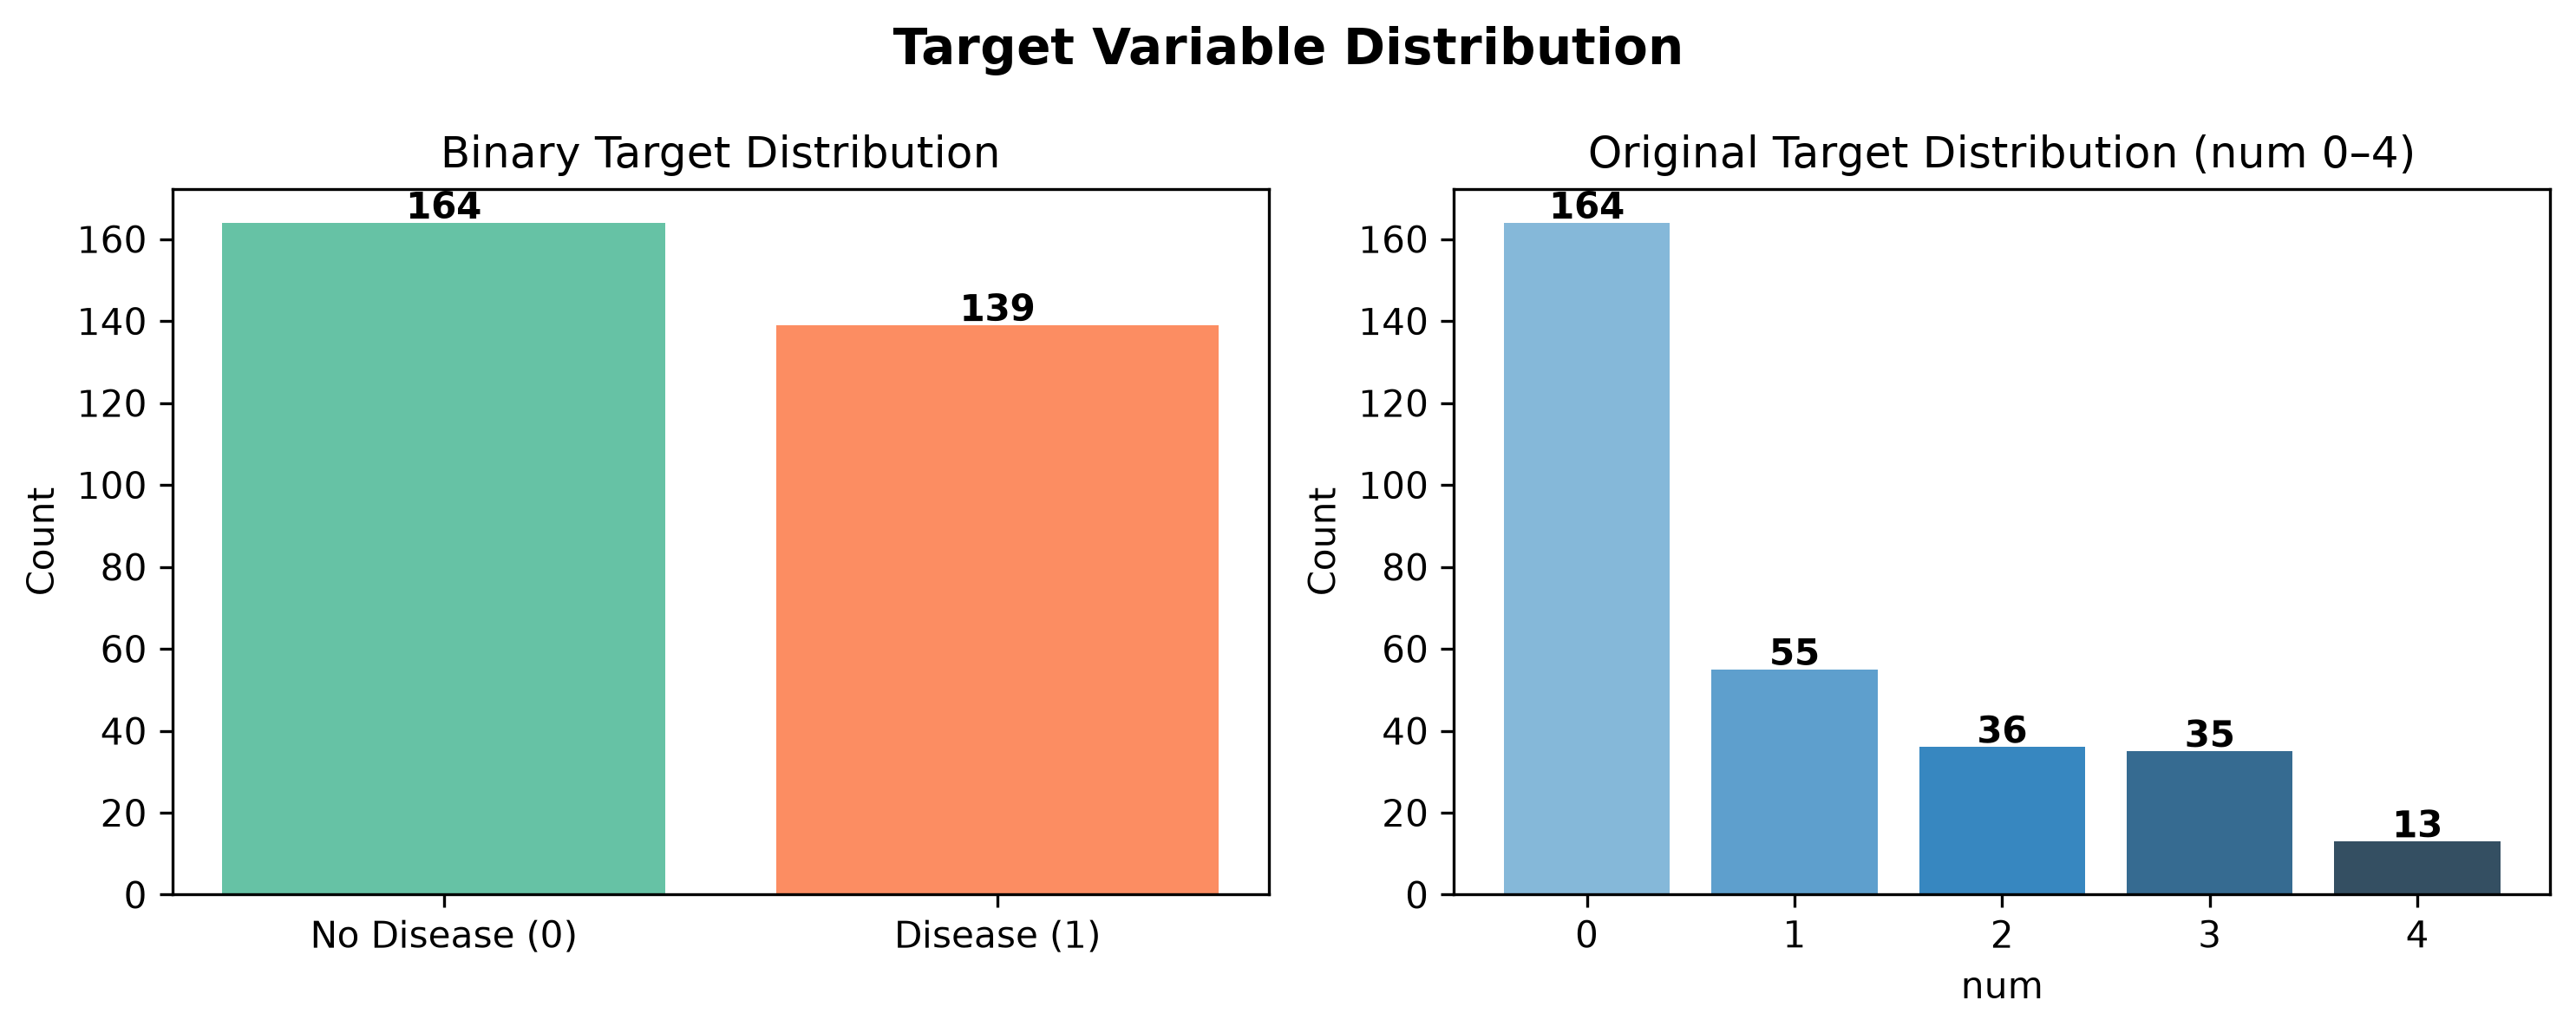

In [7]:
from IPython.display import Image
Image("../outputs/figures/fig_2_1_target_distribution.png")


**Interpretation:**  
54.1% no disease (n=164) vs 45.9% disease (n=139). Mild imbalance; stratified split is sufficient.
Among the original classes, num=0 (no disease) is dominant, while num=1 and num=2 together account for
most disease cases. We collapse all disease grades into one class as per the assignment.


### 2.3 Histograms of Numeric Features by Target

**What:** Distribution of each numeric predictor, coloured by target class.  
**Why:** Identifies separation between disease/no-disease and skewness; informs preprocessing decisions.


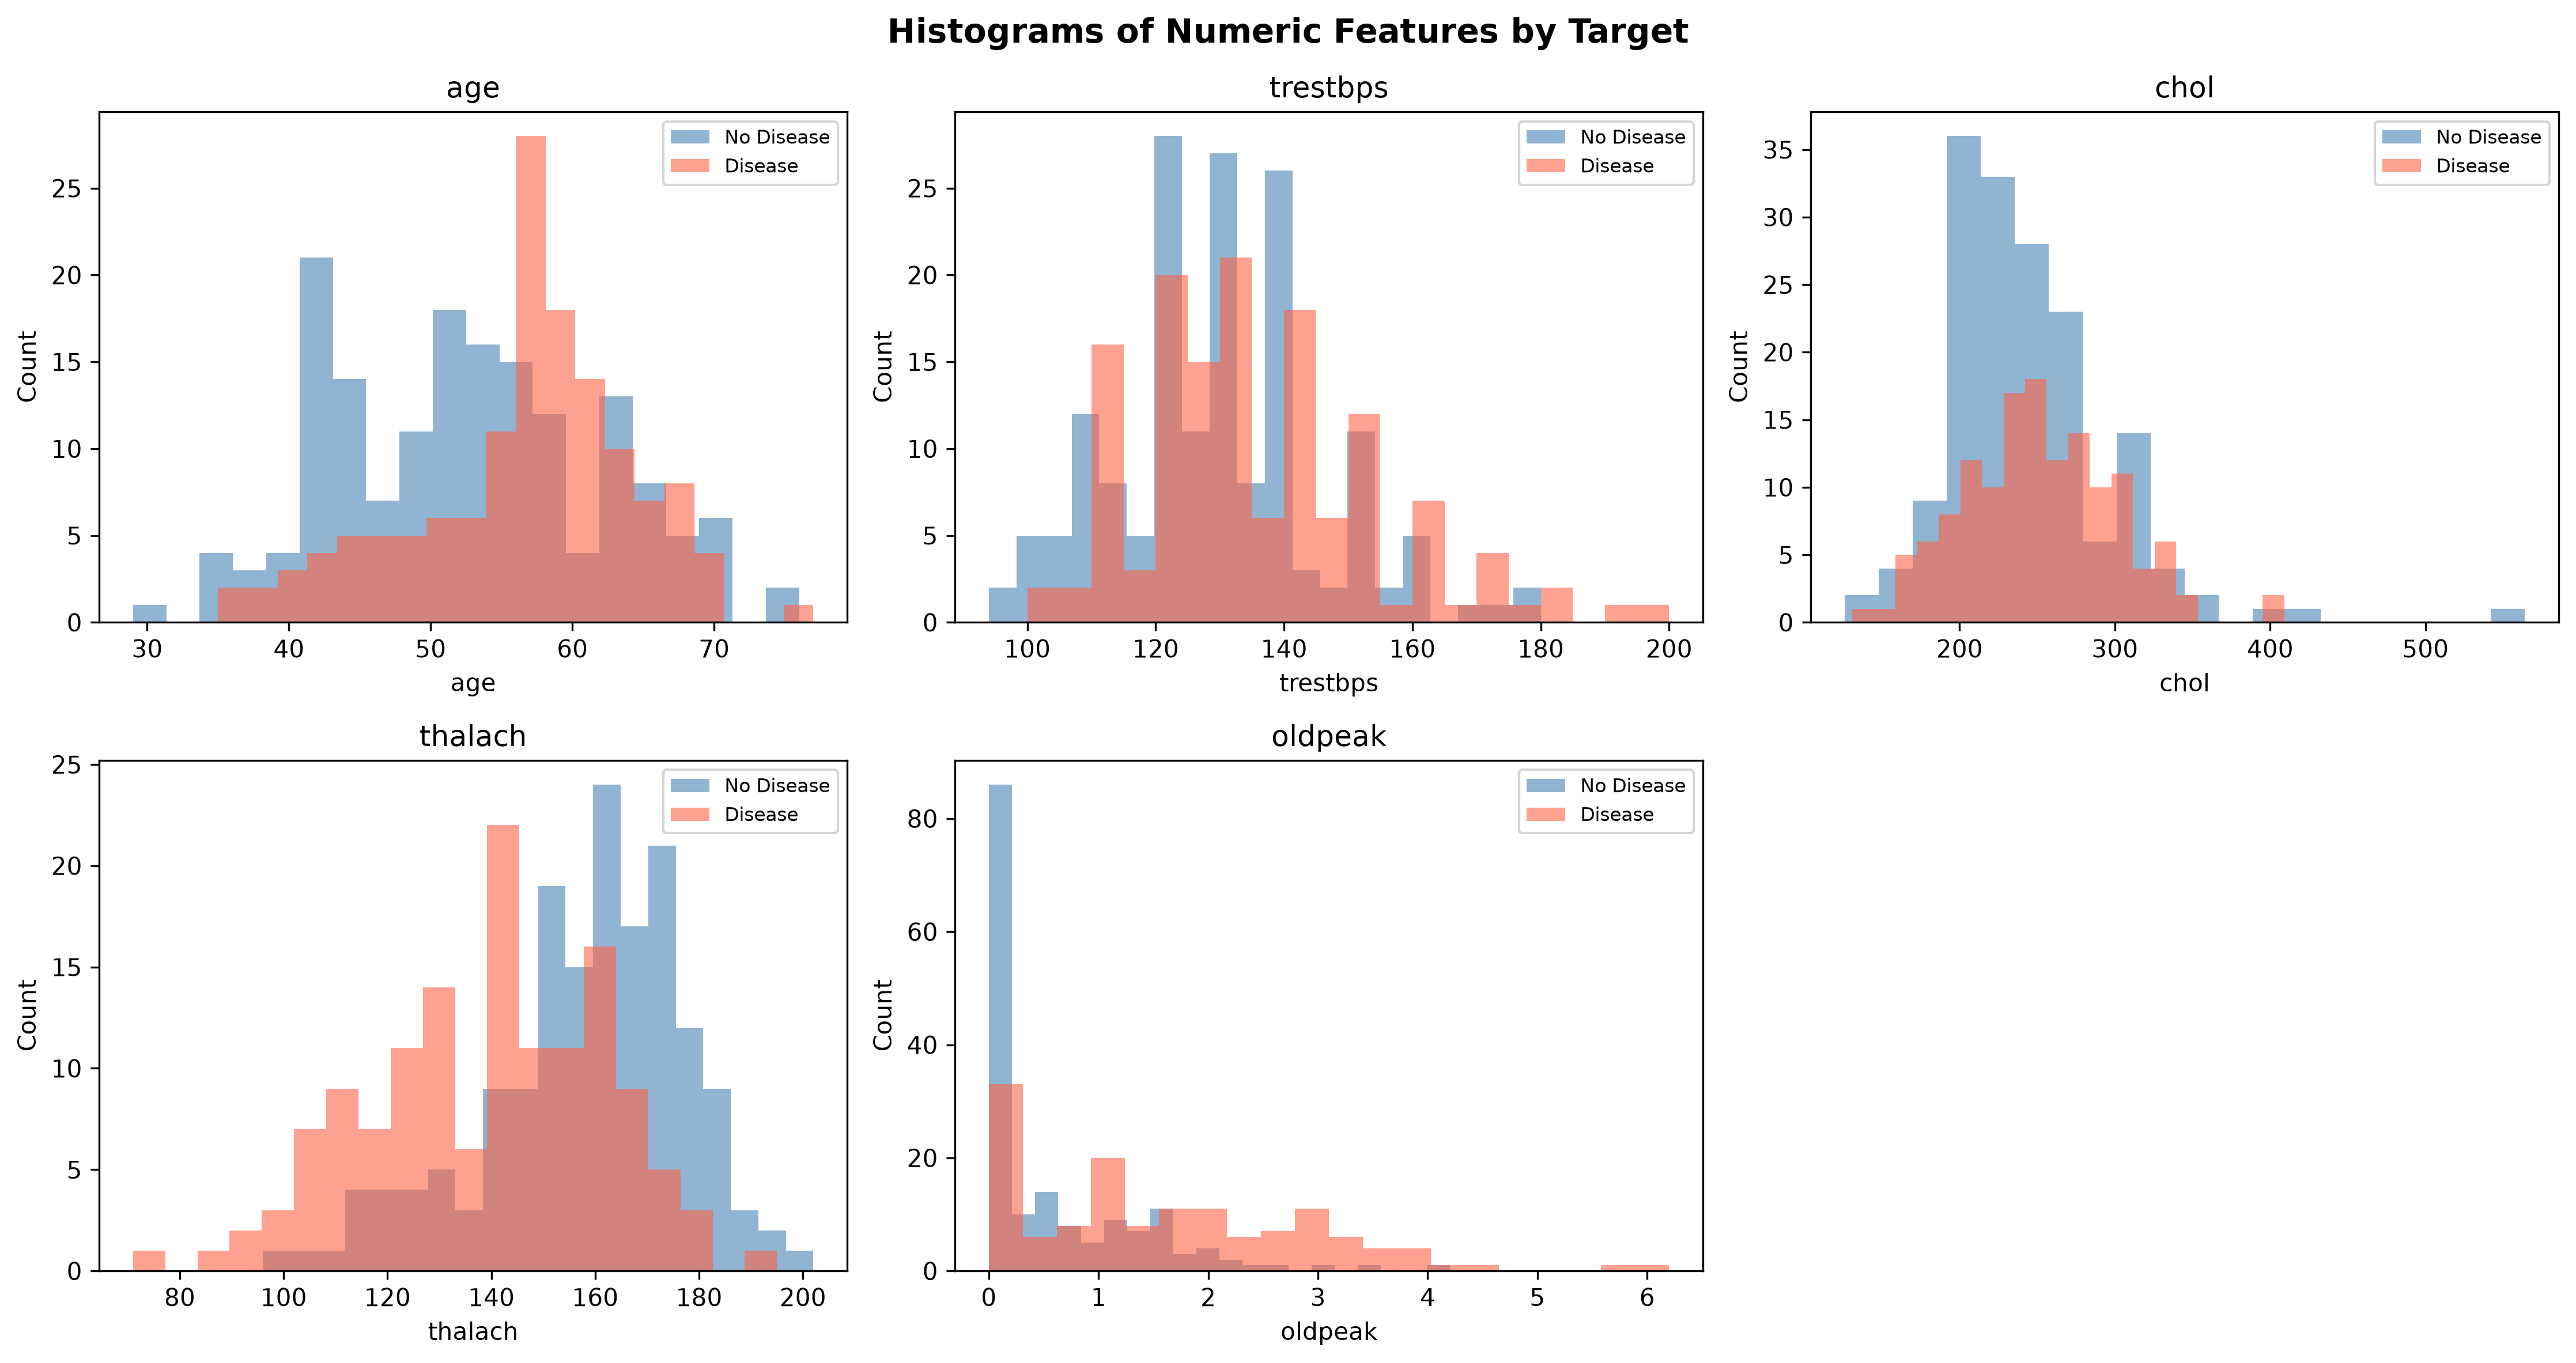

In [8]:
Image("../outputs/figures/fig_2_2_numeric_histograms.png")


**Interpretation:**  
- `thalach` (max heart rate): Disease patients tend to have *lower* max HR — a strong separating feature.
- `age`: Slight rightward shift in disease group — older patients more at risk.
- `chol` and `trestbps` show considerable overlap between classes; less discriminative alone.
- `oldpeak` has a positive skew; most patients have low ST depression, but disease patients have higher values.


### 2.4 Box Plots of Numeric Features by Target


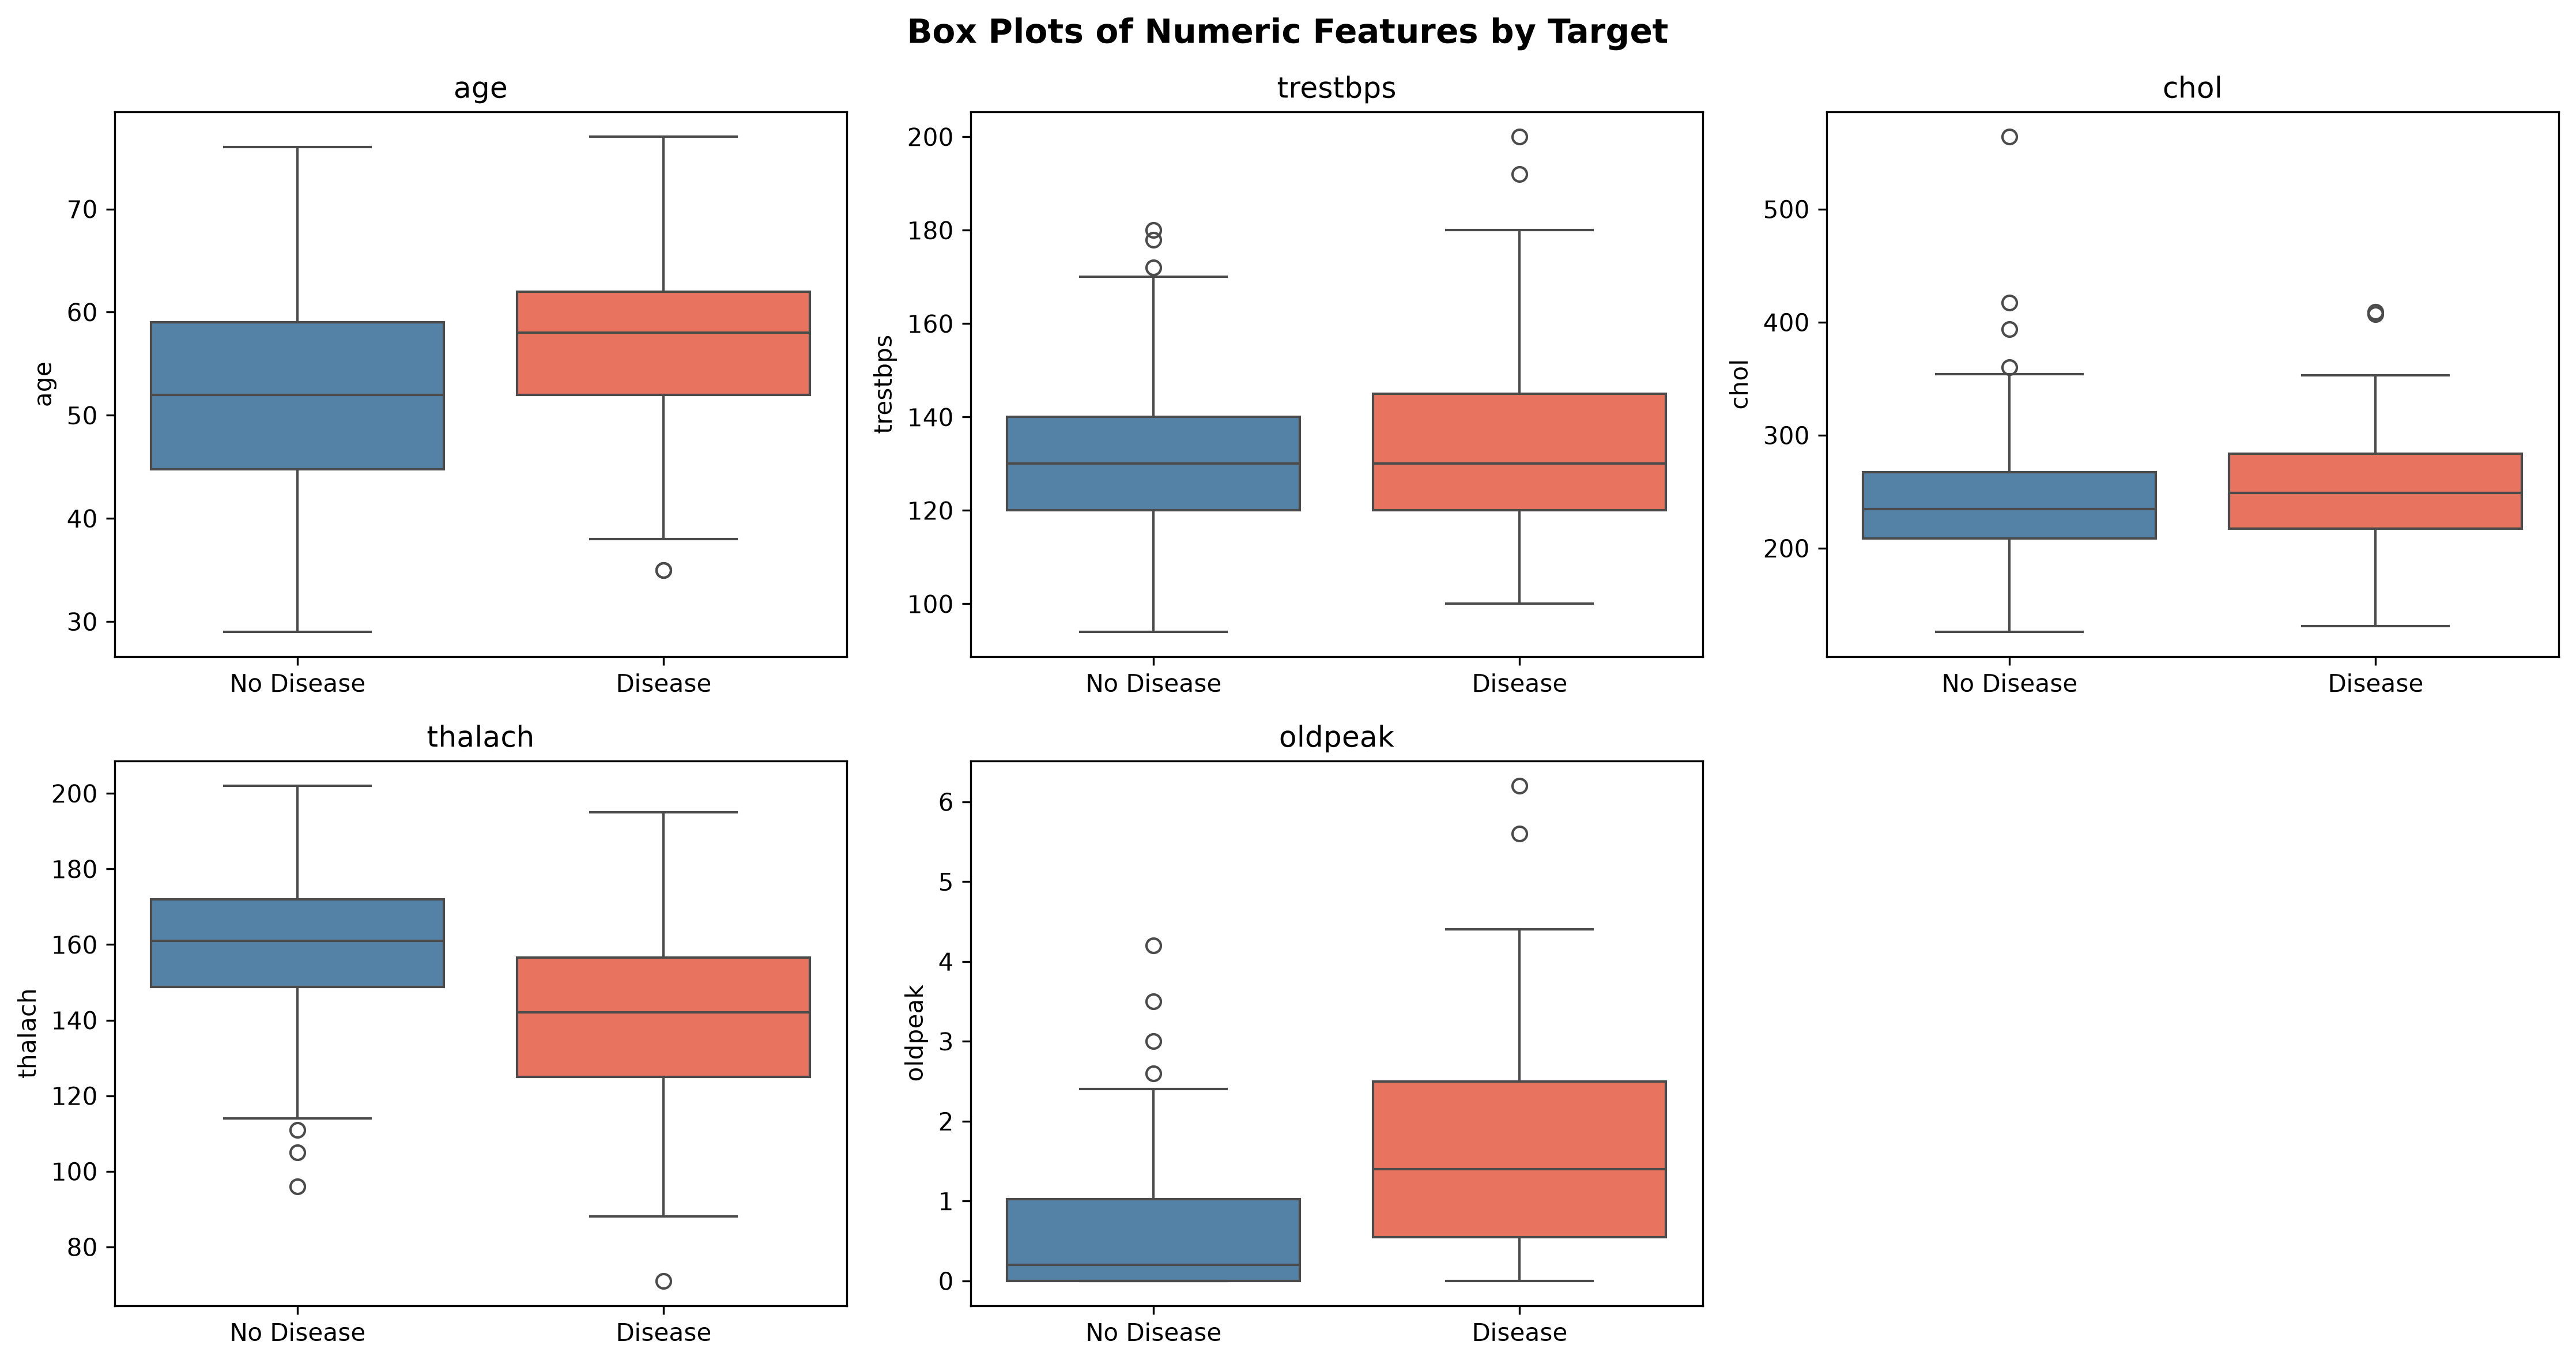

In [9]:
Image("../outputs/figures/fig_2_3_boxplots_by_target.png")


**Interpretation:**  
Box plots confirm the histogram findings. `thalach` and `oldpeak` show the clearest median separation
between disease/no-disease groups. `trestbps` and `chol` medians are close but disease group has more
high-value outliers. These outliers are retained — removing them would lose ~5% of an already
small dataset, and tree-based models handle them well.


### 2.5 Categorical Feature Count Plots by Target


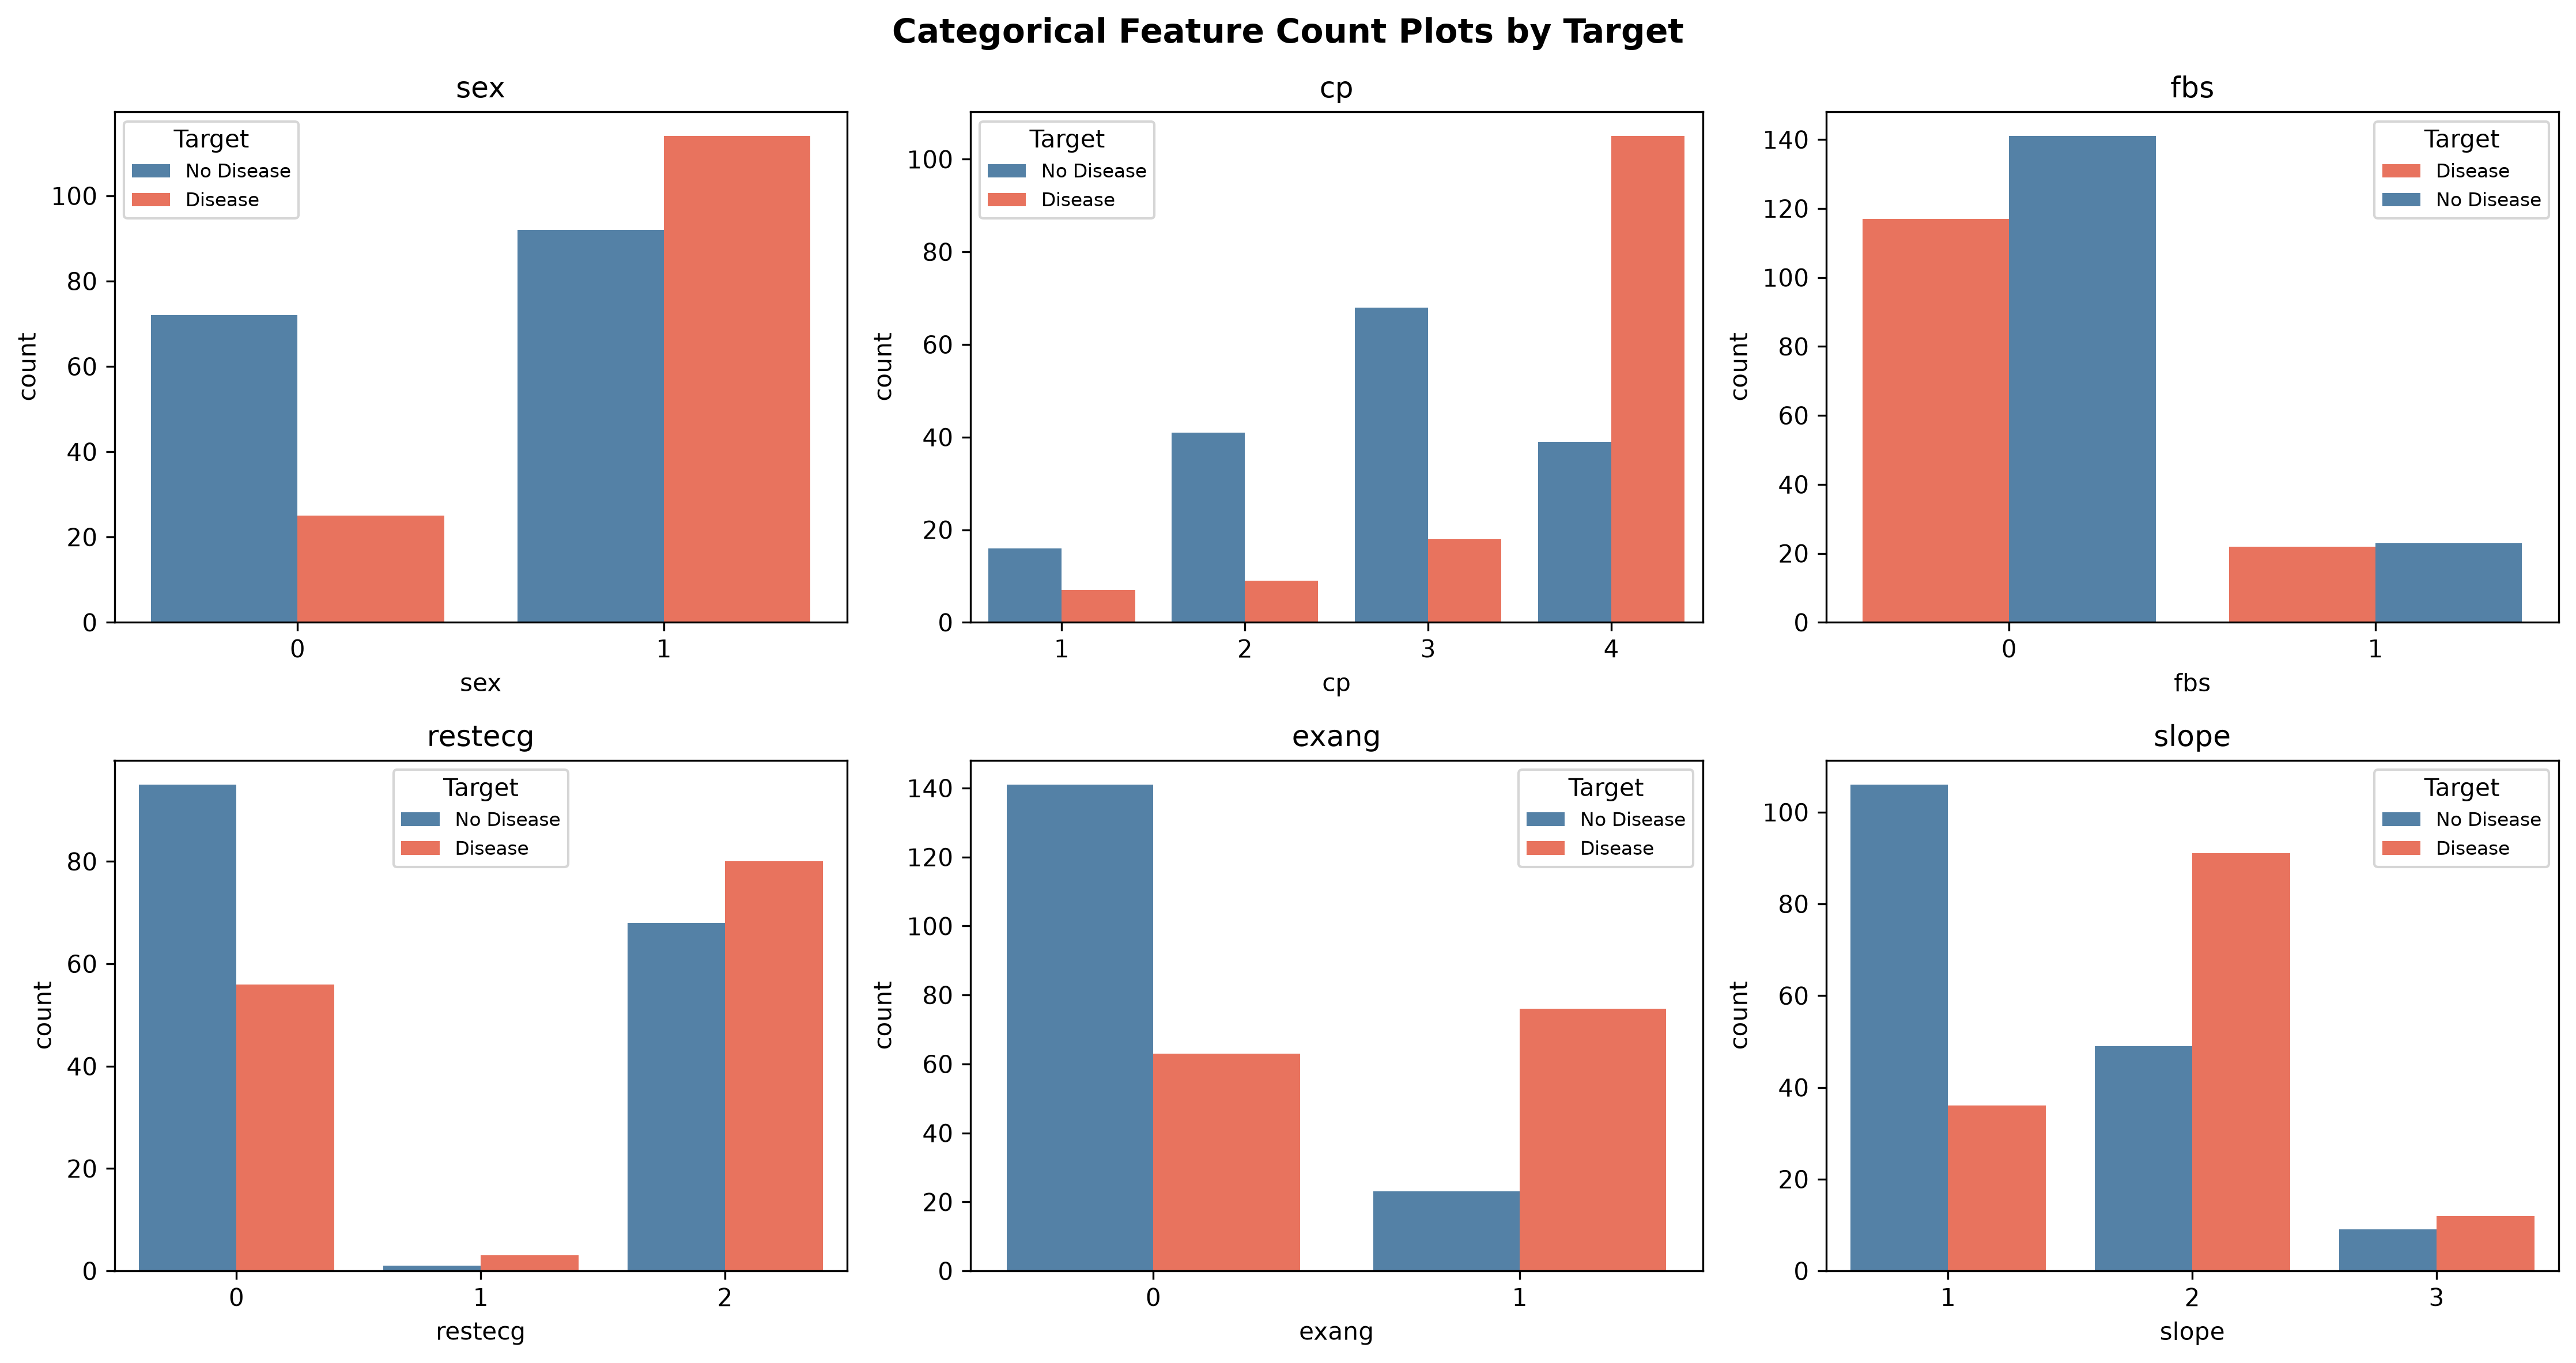

In [10]:
Image("../outputs/figures/fig_2_4_categorical_countplots.png")


**Interpretation:**  
- `cp` (chest pain type): Asymptomatic pain (cp=3/4 depending on encoding) is paradoxically most common
  in the disease group — a clinically documented phenomenon.
- `sex`: Males are over-represented in the disease group (despite being more common overall).
- `exang` (exercise-induced angina): Strong signal — disease patients more often have exang=1.
- `thal` and `ca` (not shown here, in Set B) are strong predictors per the literature.


### 2.6 Correlation Heatmap


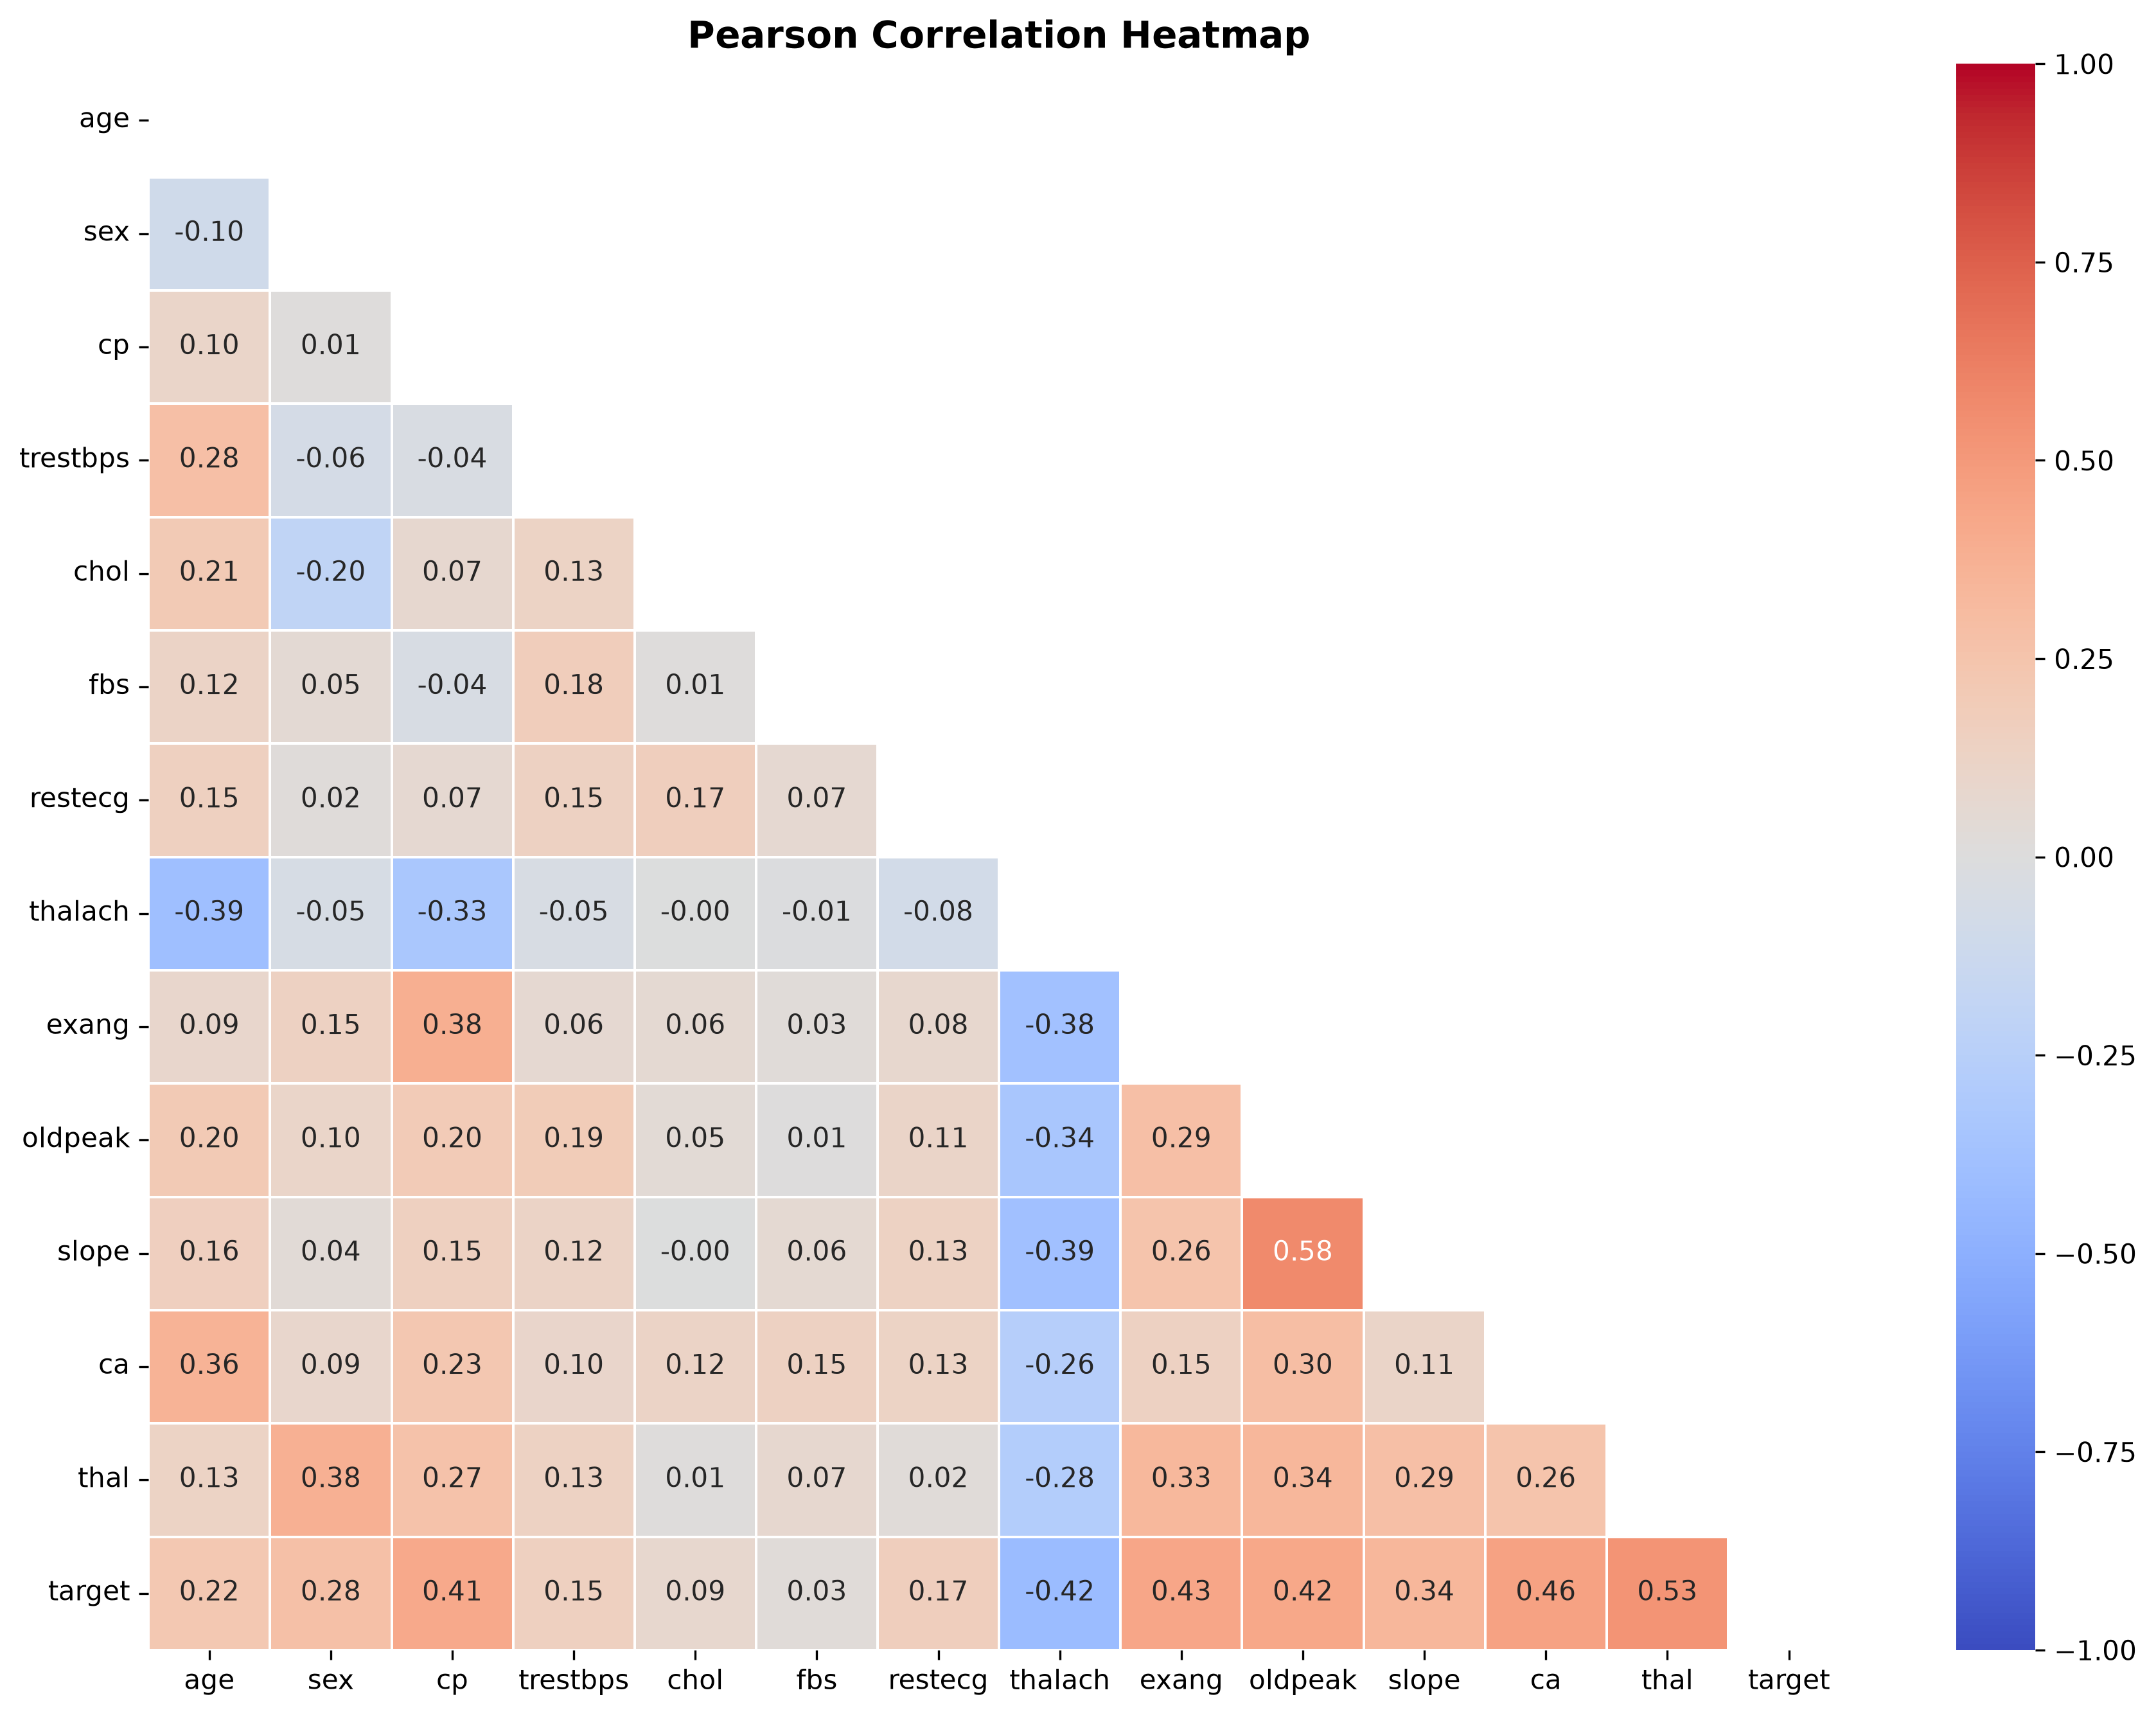

In [11]:
Image("../outputs/figures/fig_2_5_correlation_heatmap.png")


**Interpretation:**  
- `thalach` has a moderate negative correlation with target (higher max HR → less disease risk).
- `exang` and `oldpeak` have positive correlations with target.
- Many features have low pairwise correlations with each other — multicollinearity is not a major concern.
- `cp` correlates moderately with target, confirming its importance.


### 2.7 IQR Outlier Check


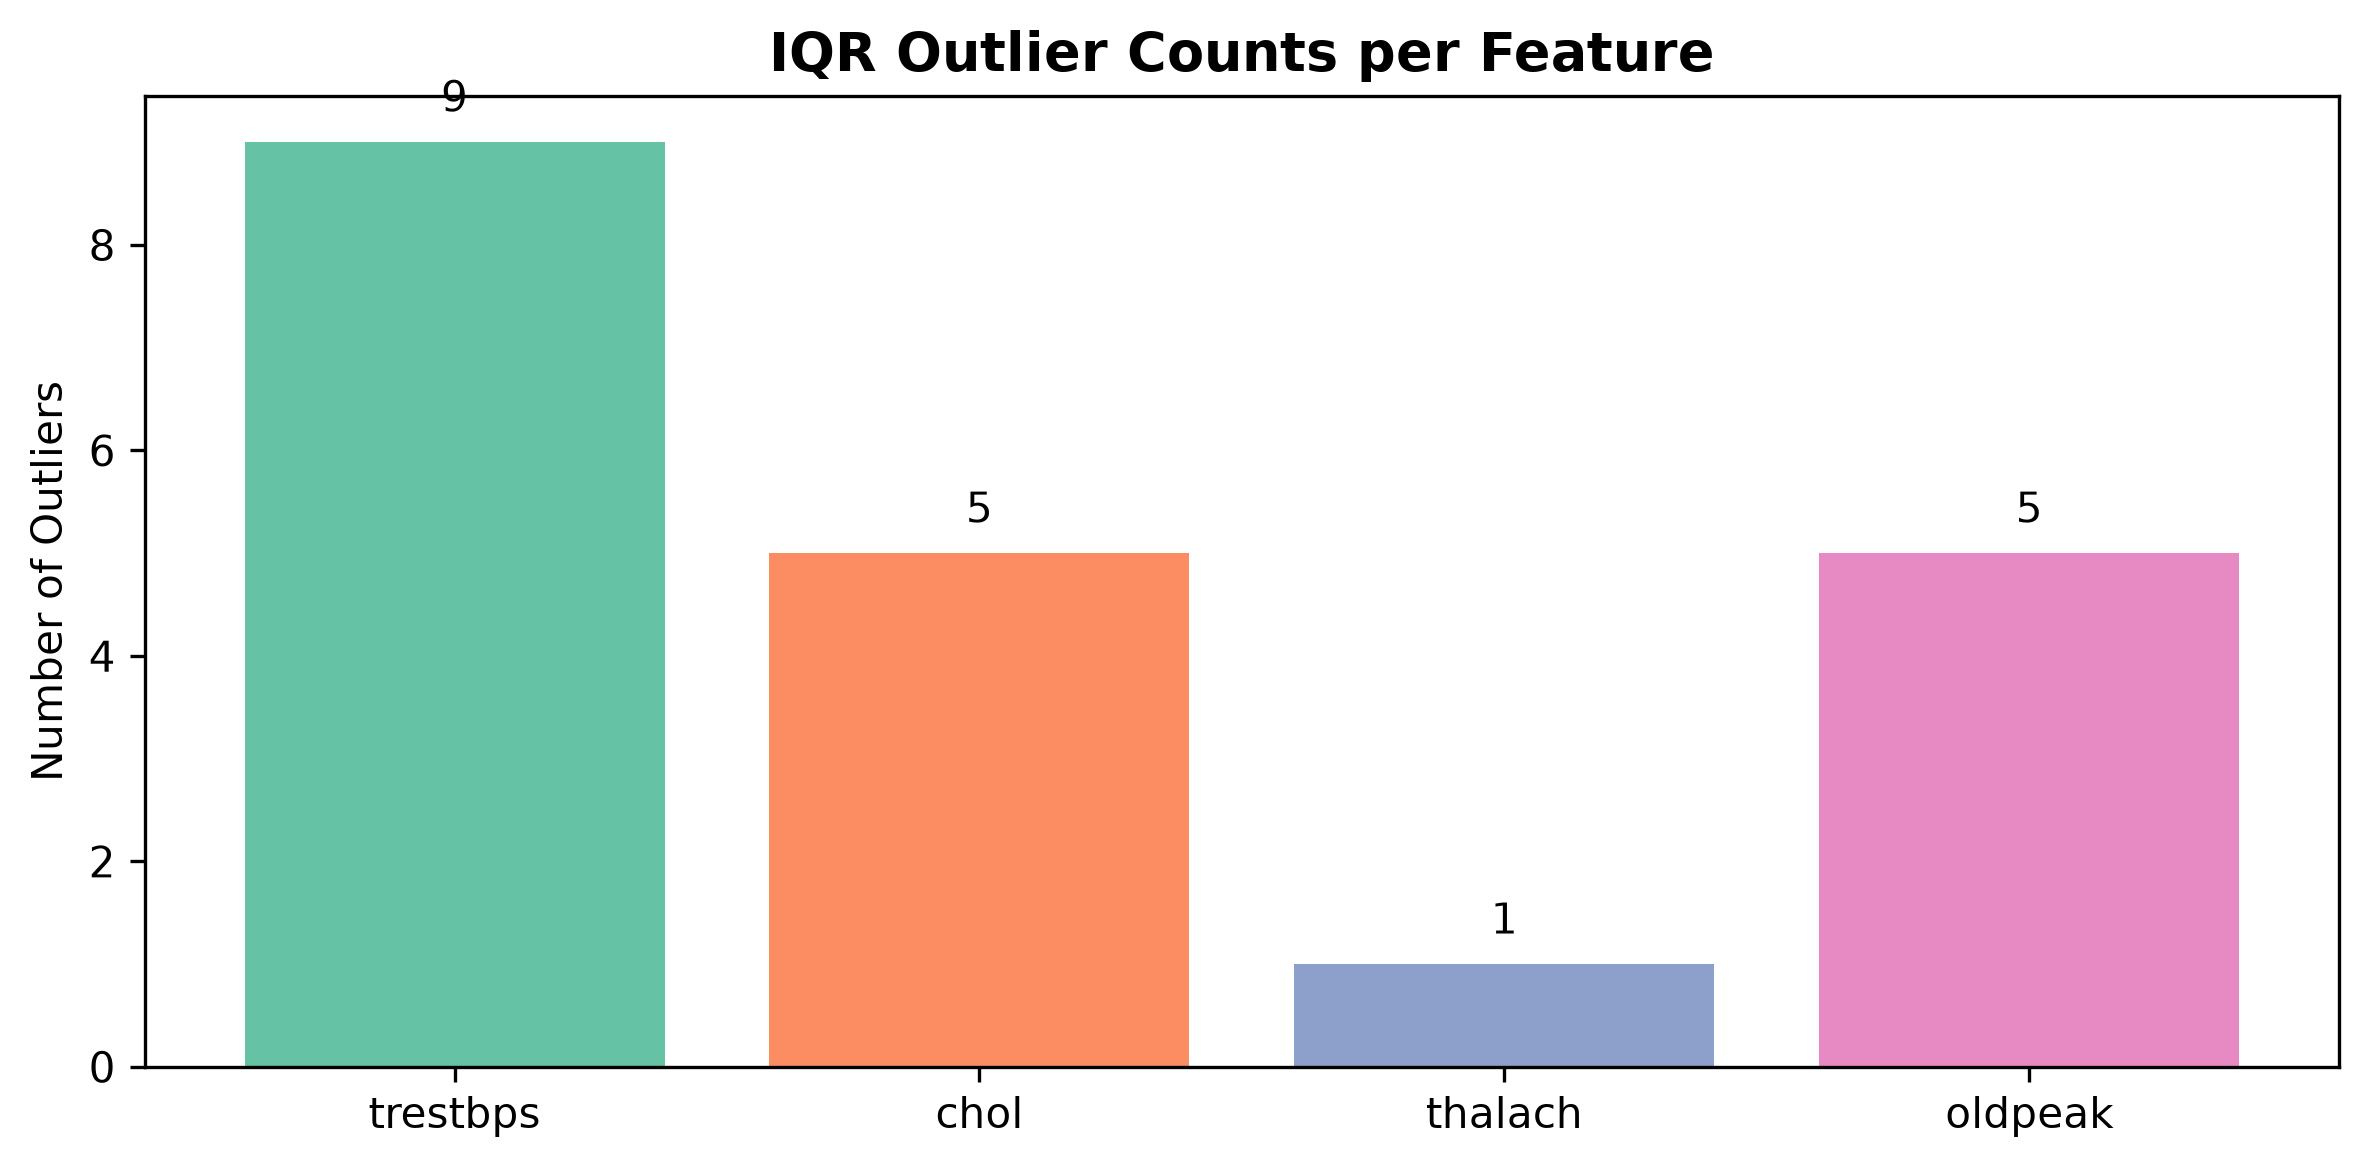

In [12]:
Image("../outputs/figures/fig_2_6_iqr_outlier_counts.png")


**Interpretation:**  
IQR analysis identifies a small number of statistical outliers in `trestbps`, `chol`, `thalach`,
and `oldpeak`. We **retain all outliers** because:
1. The dataset has only 303 rows — removing 5–9 rows per feature would cumulatively reduce the dataset significantly.
2. Decision Trees and Random Forests are inherently robust to outliers (split-based).
3. StandardScaler (inside the pipeline) reduces but doesn't eliminate outlier influence for linear models.
4. Clinical extremes (very high blood pressure, very low max HR) may genuinely indicate disease.

> **Decision:** Outliers retained. Mentioned in every relevant markdown cell.


## 3. Preprocessing Pipeline

**What:** Build sklearn `Pipeline` + `ColumnTransformer` for each feature set.  
**Why:** Encapsulating all preprocessing in a Pipeline is essential to prevent **data leakage**:
the imputer and scaler must learn statistics only from the training fold, not from the test set.

### Preprocessing steps:
1. **Median imputation** for numeric features (handles ca and thal NaNs)
2. **Most-frequent imputation** for nominal features (cp, if any missing)
3. **StandardScaler** on all numeric features (required for LR, KNN, SVM)
4. **OneHotEncoder** for `cp` (nominal with 4 categories)

> ⚠️ **No-Leakage Confirmation:** All `SimpleImputer`, `StandardScaler`, and `OneHotEncoder`
> objects are inside `Pipeline` / `ColumnTransformer`. They are `fit()` exclusively on the
> **training data** (or the training fold within each GridSearchCV split).
> The test set is never seen during any fitting step.
> Feature selection (MI, RF importance) is computed only on the training partition after splitting.


In [13]:
from src.preprocessing import build_preprocessor, SET_A_FEATURES, SET_B_FEATURES
preprocessor_A = build_preprocessor(SET_A_FEATURES)
print("Feature Set A preprocessor steps:")
print(preprocessor_A)


Feature Set A preprocessor steps:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'sex', 'trestbps', 'chol', 'thalach']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['cp'])])


## 4. Stratified Train/Test Split (80/20)

**What:** Split the data 80% train / 20% test using stratified sampling.  
**Why:** Stratification ensures the same class proportion in both splits, preventing a scenario
where one split has disproportionately more disease cases. `random_state=42` for reproducibility.


In [14]:
X = df[SET_B_FEATURES]
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

split_df = pd.read_csv("../outputs/tables/table_split_sizes.csv")
print(split_df.to_string(index=False))
print(f"\nClass ratio in train: {dict(y_train.value_counts().sort_index())}")
print(f"Class ratio in test:  {dict(y_test.value_counts().sort_index())}")


Subset  Records   Pct  No_Disease  Disease
 Train      242 79.9%         131      111
  Test       61 20.1%          33       28

Class ratio in train: {0: np.int64(131), 1: np.int64(111)}
Class ratio in test:  {0: np.int64(33), 1: np.int64(28)}


**Interpretation:**  
- Train: 242 rows (79.9%); Test: 61 rows (20.1%).
- Class proportions preserved: ~54/46 split maintained in both subsets.
- **Caveat:** The test set has only ~61 samples. With this small test size, differences of a few
  percentage points in accuracy or F1 between models may be within sampling noise. The repeated
  CV results (Section 7) provide a more stable performance estimate using the full dataset.


## 5. Feature Selection (Set C)

**What:** Use Mutual Information (MI) and Random Forest importance scores (both computed only on
training data) to automatically select the most informative features.  
**Why:** Feature selection can reduce overfitting, improve interpretability, and sometimes boost
generalisation — especially on small datasets.

### Method:
- Compute MI scores for all features using `mutual_info_classif` on the training data
- Compute RF importance scores using a 200-tree forest fitted on training data
- Normalise both scores, average them → combined score
- **Cutoff:** MI score ≥ 0.05 (captures features contributing >5% of mutual information signal)
  - Below this threshold, features add noise more than signal on this dataset size.


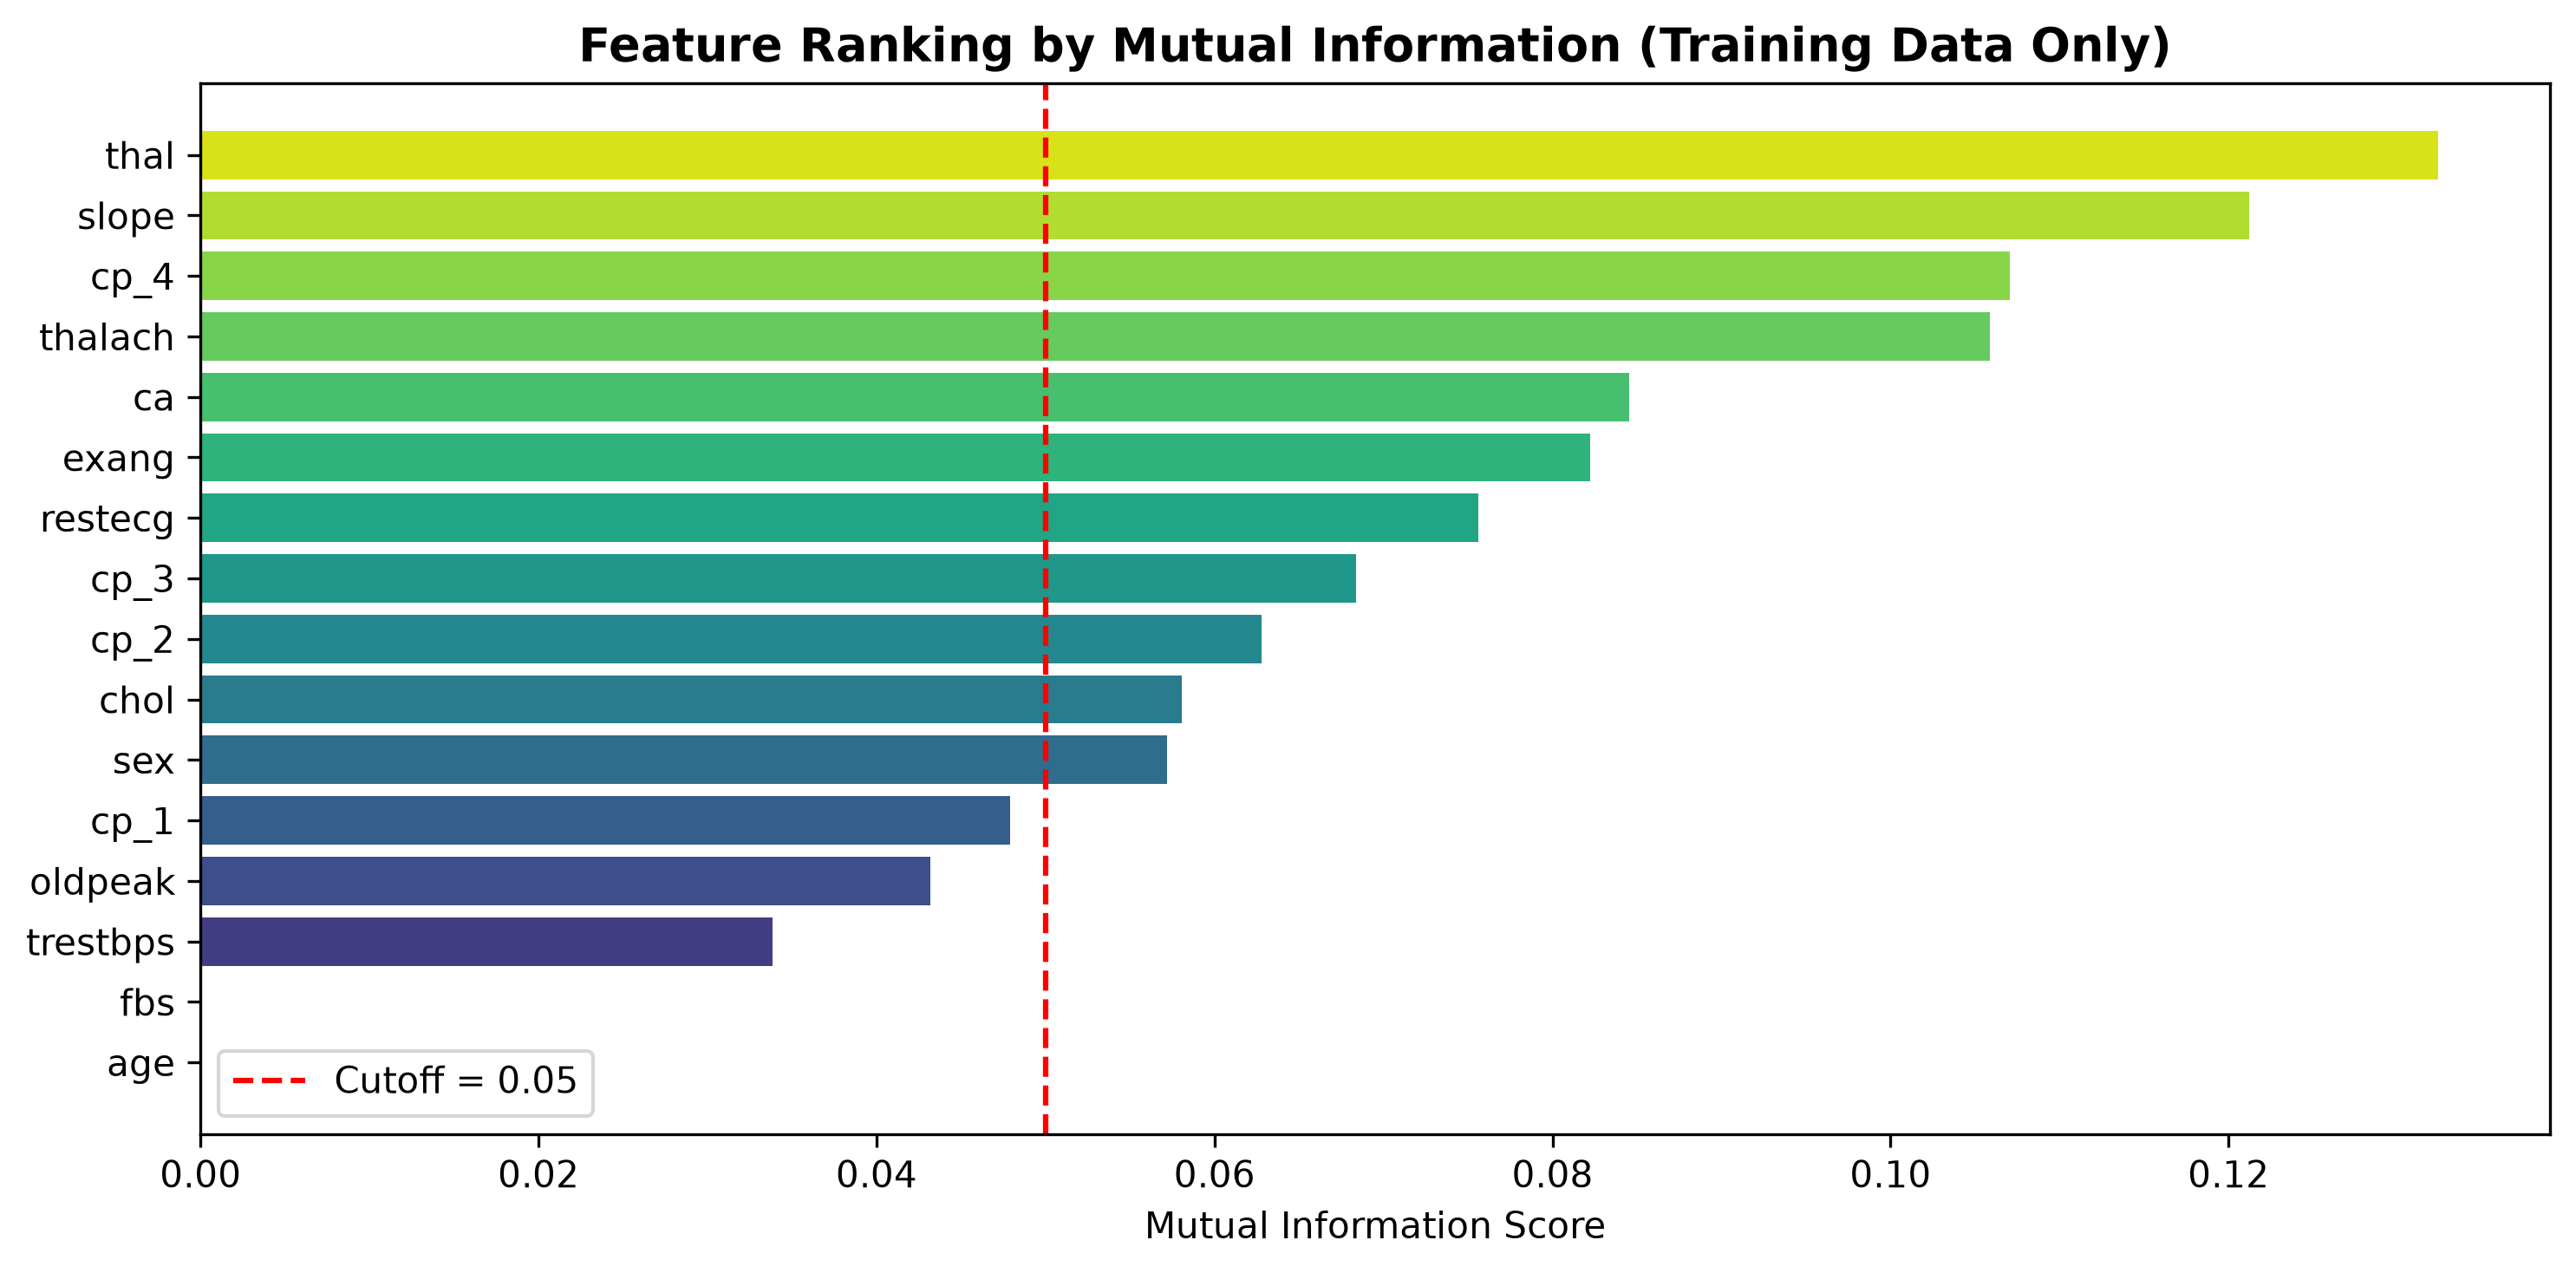

In [15]:
Image("../outputs/figures/fig_3_1_mutual_information_scores.png")


In [16]:
feat_sel_df = pd.read_csv("../outputs/tables/table_feature_selection.csv")
print(feat_sel_df.to_string(index=False))
feat_sel_df


 Feature Set_A Set_B Set_C  MI_Score  RF_Importance                       Reason
     age     ✓     ✓     ✗    0.0000         0.0843           Assignment primary
     sex     ✓     ✓     ✓    0.0572         0.0346           Assignment primary
      cp     ✓     ✓     ✓    0.1071         0.0963           Assignment primary
trestbps     ✓     ✓     ✗    0.0339         0.0714           Assignment primary
    chol     ✓     ✓     ✓    0.0580         0.0885           Assignment primary
     fbs     ✗     ✓     ✗    0.0000         0.0103 MI < cutoff, excluded from C
 restecg     ✗     ✓     ✓    0.0756         0.0206                 MI >= cutoff
 thalach     ✓     ✓     ✓    0.1059         0.1079           Assignment primary
   exang     ✗     ✓     ✓    0.0823         0.0484                 MI >= cutoff
 oldpeak     ✗     ✓     ✗    0.0432         0.0983 MI < cutoff, excluded from C
   slope     ✗     ✓     ✓    0.1212         0.0431                 MI >= cutoff
      ca     ✗     ✓     ✓  

,Feature,Set_A,Set_B,Set_C,MI_Score,RF_Importance,Reason
0,age,✓,✓,✗,0.0000,0.0843,Assignment primary
1,sex,✓,✓,✓,0.0572,0.0346,Assignment primary
2,cp,✓,✓,✓,0.1071,0.0963,Assignment primary
3,trestbps,✓,✓,✗,0.0339,0.0714,Assignment primary
4,chol,✓,✓,✓,0.0580,0.0885,Assignment primary
5,fbs,✗,✓,✗,0.0000,0.0103,"MI < cutoff, excluded from C"
6,restecg,✗,✓,✓,0.0756,0.0206,MI >= cutoff
7,thalach,✓,✓,✓,0.1059,0.1079,Assignment primary
8,exang,✗,✓,✓,0.0823,0.0484,MI >= cutoff
9,oldpeak,✗,✓,✗,0.0432,0.0983,"MI < cutoff, excluded from C"


**Interpretation:**  
- `thal`, `ca`, `cp`, `thalach`, and `slope` score highest on mutual information — consistent with
  the clinical literature (thalassemia type and vessel count are strong predictors).
- `fbs` (fasting blood sugar) and `oldpeak` score below the cutoff; excluded from Set C.
- Set A features (`age, sex, cp, trestbps, chol, thalach`) include the moderate-to-high scorers
  from that group. The absence of `ca` and `thal` limits Set A's performance vs Sets B and C.


## 6. Model Training & Hyperparameter Tuning

**What:** Train and tune 5 classifiers (Logistic Regression, KNN, Decision Tree, SVM, Random Forest)
using `GridSearchCV` with `StratifiedKFold(5)` and `scoring='f1'` on all three feature sets.  
**Why:** F1 is the primary metric because in cardiac screening, recall (catching all disease cases)
is more important than precision. F1 balances both. GridSearchCV exhaustively searches the
hyperparameter space and selects the configuration that maximises CV F1.

> **Note:** This notebook loads pre-computed results from `run_pipeline.py` to avoid re-running
> the full grid search (~10+ minutes). To re-tune, run `python run_pipeline.py`.


In [17]:
hp_df = pd.read_csv("../outputs/tables/table_hyperparameters.csv")
# Show Set A only for brevity
hp_A = hp_df[hp_df["Feature_Set"] == "A"]
print("Best hyperparameters — Feature Set A:")
print(hp_A.to_string(index=False))


Best hyperparameters — Feature Set A:
             Model Feature_Set    Hyperparameter               Search_Range Selected_Value                               Method
LogisticRegression           A                 C    [0.01, 0.1, 1, 10, 100]             10 GridSearchCV (StratifiedKFold-5, F1)
LogisticRegression           A            solver     ['liblinear', 'lbfgs']      liblinear GridSearchCV (StratifiedKFold-5, F1)
               KNN           A            metric ['euclidean', 'manhattan']      manhattan GridSearchCV (StratifiedKFold-5, F1)
               KNN           A       n_neighbors       [3, 5, 7, 9, 11, 15]              5 GridSearchCV (StratifiedKFold-5, F1)
               KNN           A           weights    ['uniform', 'distance']       distance GridSearchCV (StratifiedKFold-5, F1)
      DecisionTree           A         criterion        ['gini', 'entropy']        entropy GridSearchCV (StratifiedKFold-5, F1)
      DecisionTree           A         max_depth      [2, 3, 4, 5,

## 7. Test-Set Evaluation

**What:** Evaluate each tuned model on the held-out test set (61 rows, never seen during training).  
**Why:** Test-set metrics give an unbiased estimate of generalisation performance.
We report accuracy, precision, recall, F1 (disease class), and ROC-AUC.

We also examine **False Negatives (FN) vs False Positives (FP)**:  
In cardiac screening, an FN (missing a true disease case) is far more costly than an FP
(sending a healthy patient for further tests). We therefore pay special attention to Recall
and FN counts alongside F1.


### 7.1 Feature Set A (Primary — Assignment Features)


In [18]:
metrics_A = pd.read_csv("../outputs/tables/table_model_comparison_setA.csv", index_col="Model")
print(metrics_A.to_string())
metrics_A


                    Accuracy  Precision    Recall        F1   ROC_AUC
Model                                                                
LogisticRegression  0.819672   0.840000  0.750000  0.792453  0.906926
KNN                 0.868852   0.884615  0.821429  0.851852  0.908009
DecisionTree        0.819672   0.774194  0.857143  0.813559  0.909091
SVM                 0.836066   0.846154  0.785714  0.814815  0.903680
RandomForest        0.836066   0.821429  0.821429  0.821429  0.908009


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
LogisticRegression,0.819672,0.840000,0.750000,0.792453,0.906926
KNN,0.868852,0.884615,0.821429,0.851852,0.908009
DecisionTree,0.819672,0.774194,0.857143,0.813559,0.909091
SVM,0.836066,0.846154,0.785714,0.814815,0.903680
RandomForest,0.836066,0.821429,0.821429,0.821429,0.908009


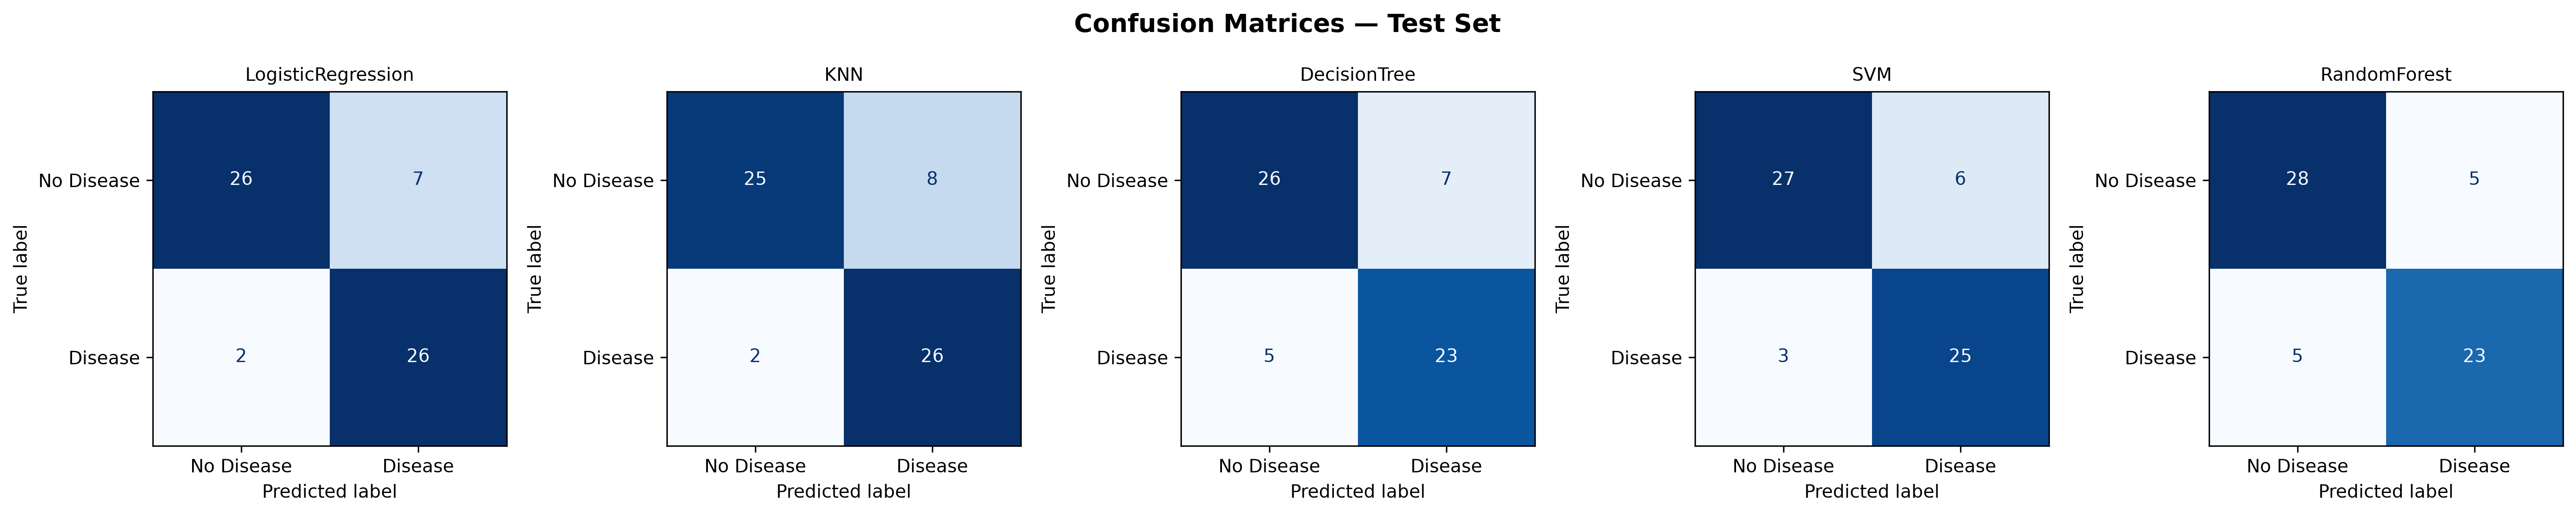

In [19]:
Image("../outputs/figures/fig_4_1_confusion_matrices_grid.png")


**Interpretation (Set A Confusion Matrices):**  
Inspect False Negatives (bottom-left cell = predicted No Disease, actual Disease) across models.
Lower FN counts indicate better recall on the disease class — the most clinically important metric.


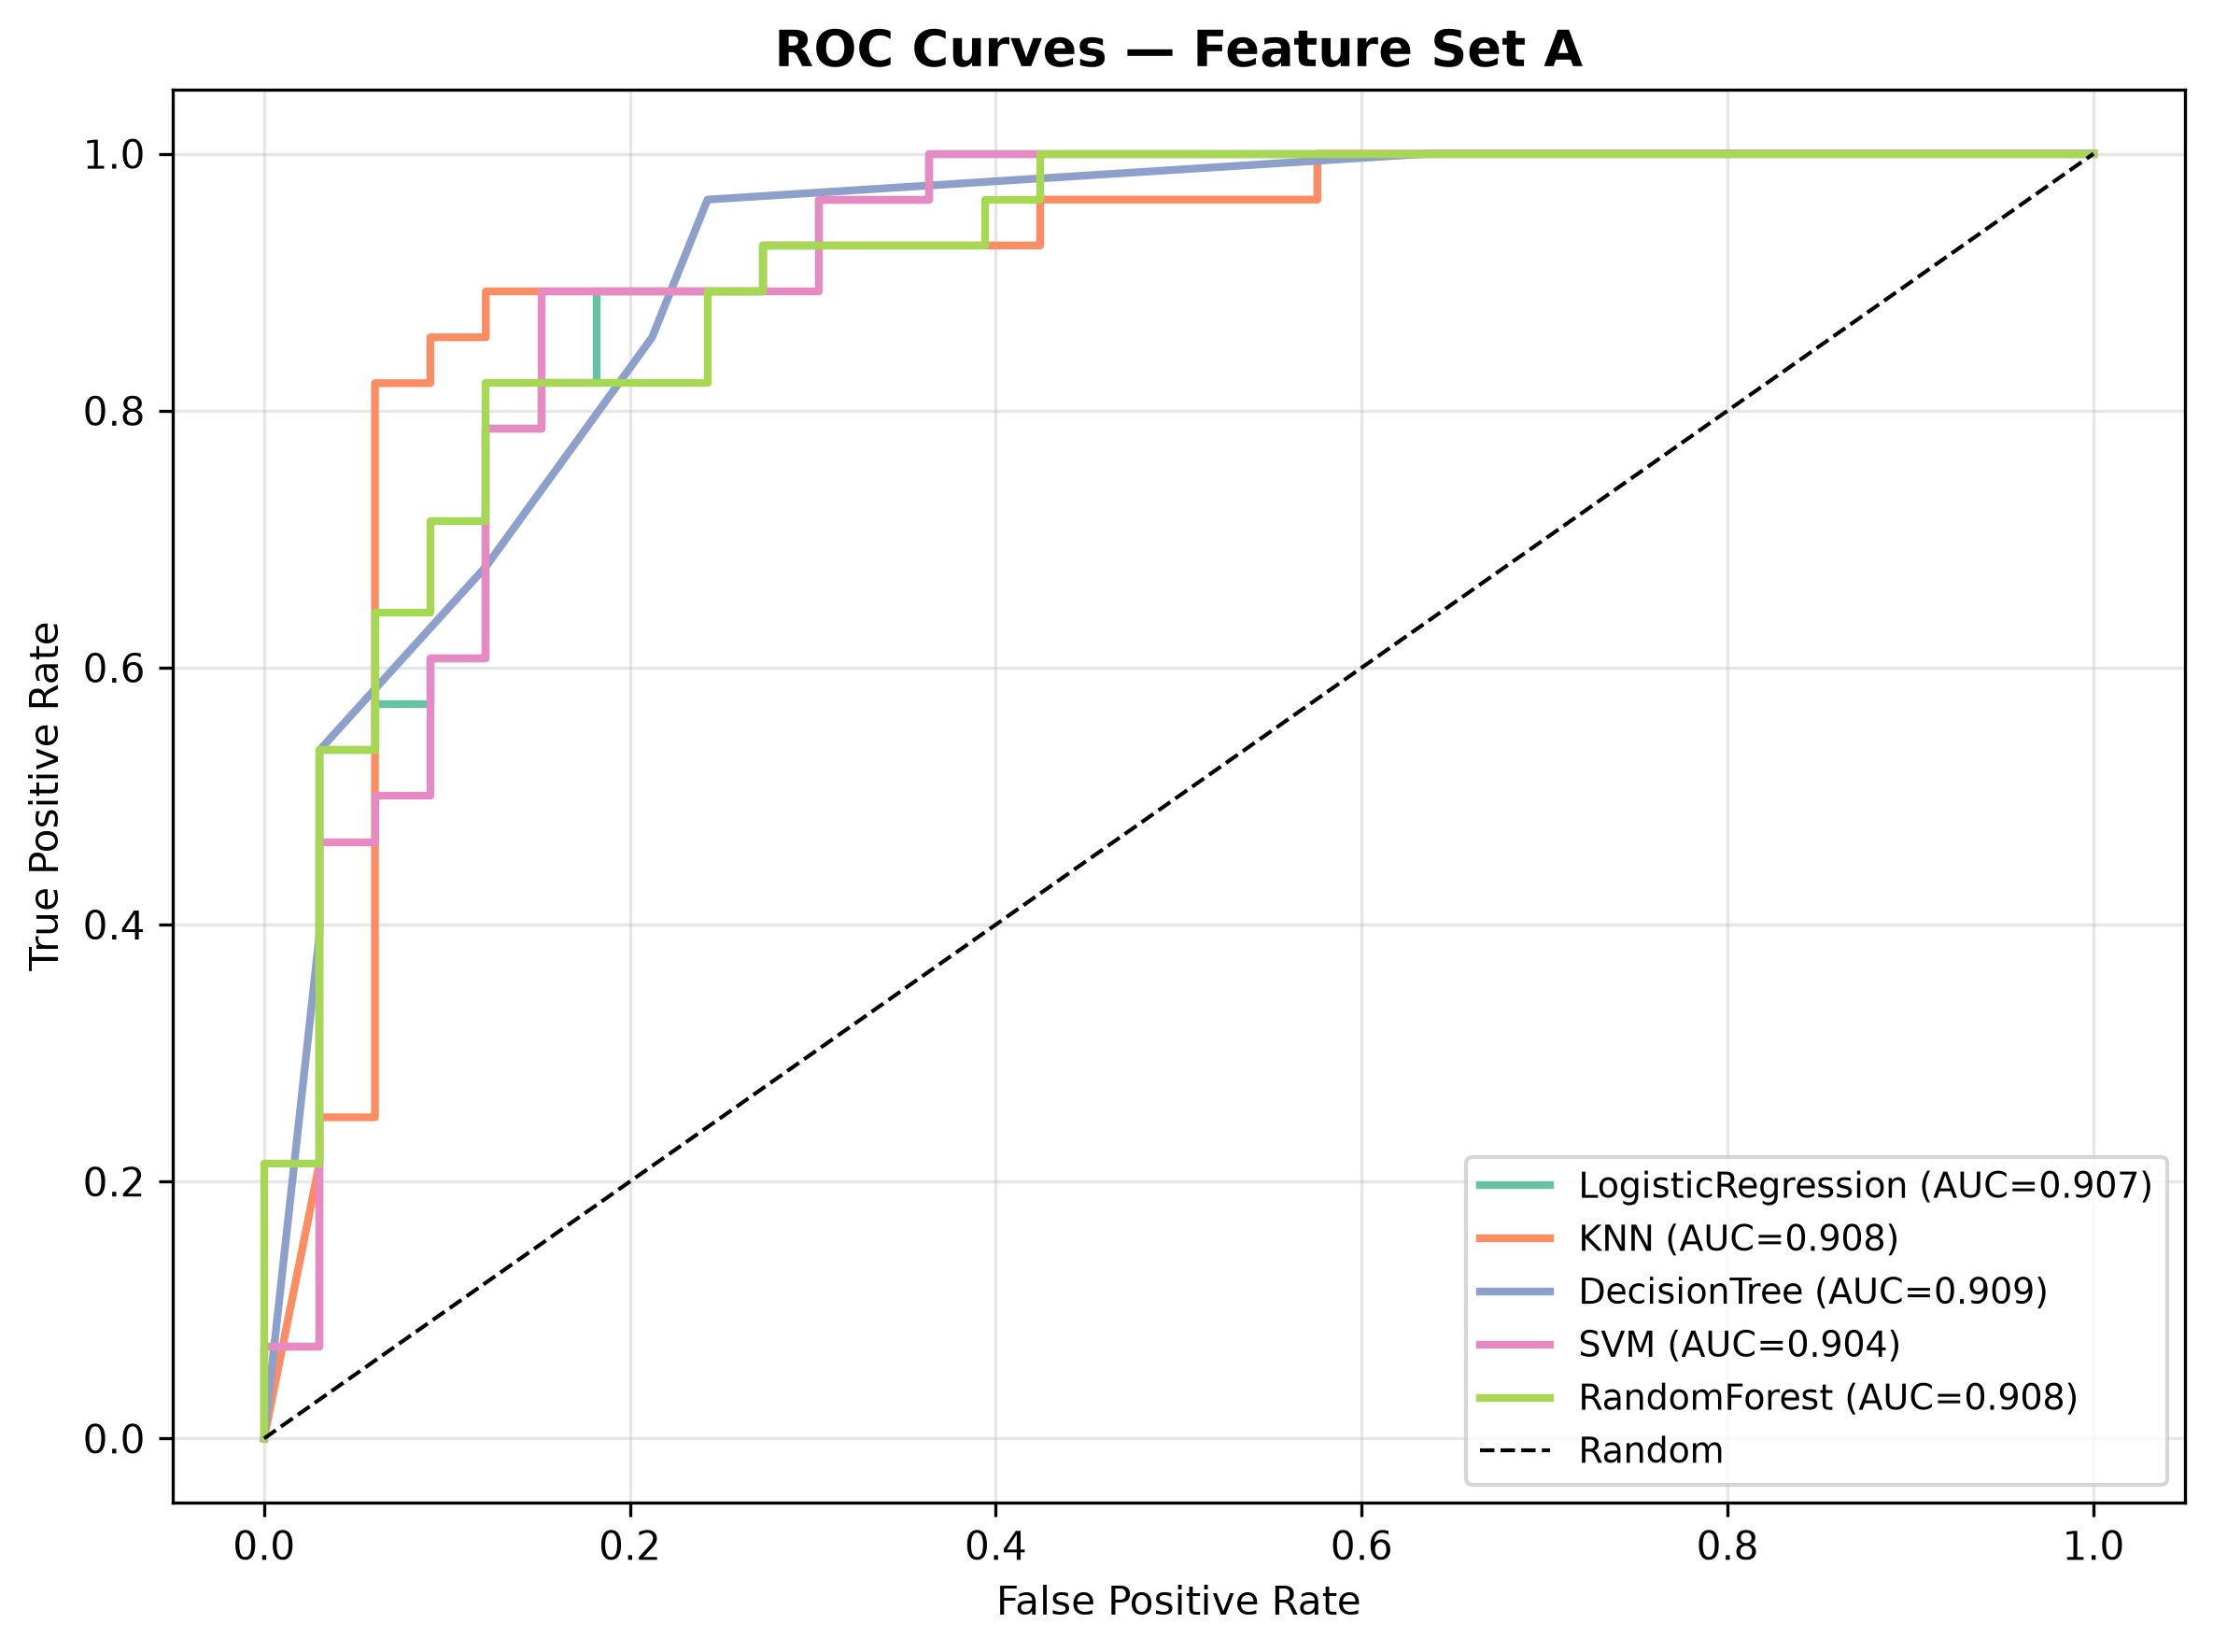

In [20]:
Image("../outputs/figures/fig_4_2_roc_curves_setA.png")


**Interpretation (Set A ROC Curves):**  
All 5 models achieve AUC > 0.90 on the assignment feature set — strong discriminative performance
given only 6 features. KNN and Random Forest track closely. ROC-AUC is threshold-independent
and complements the F1 metric.


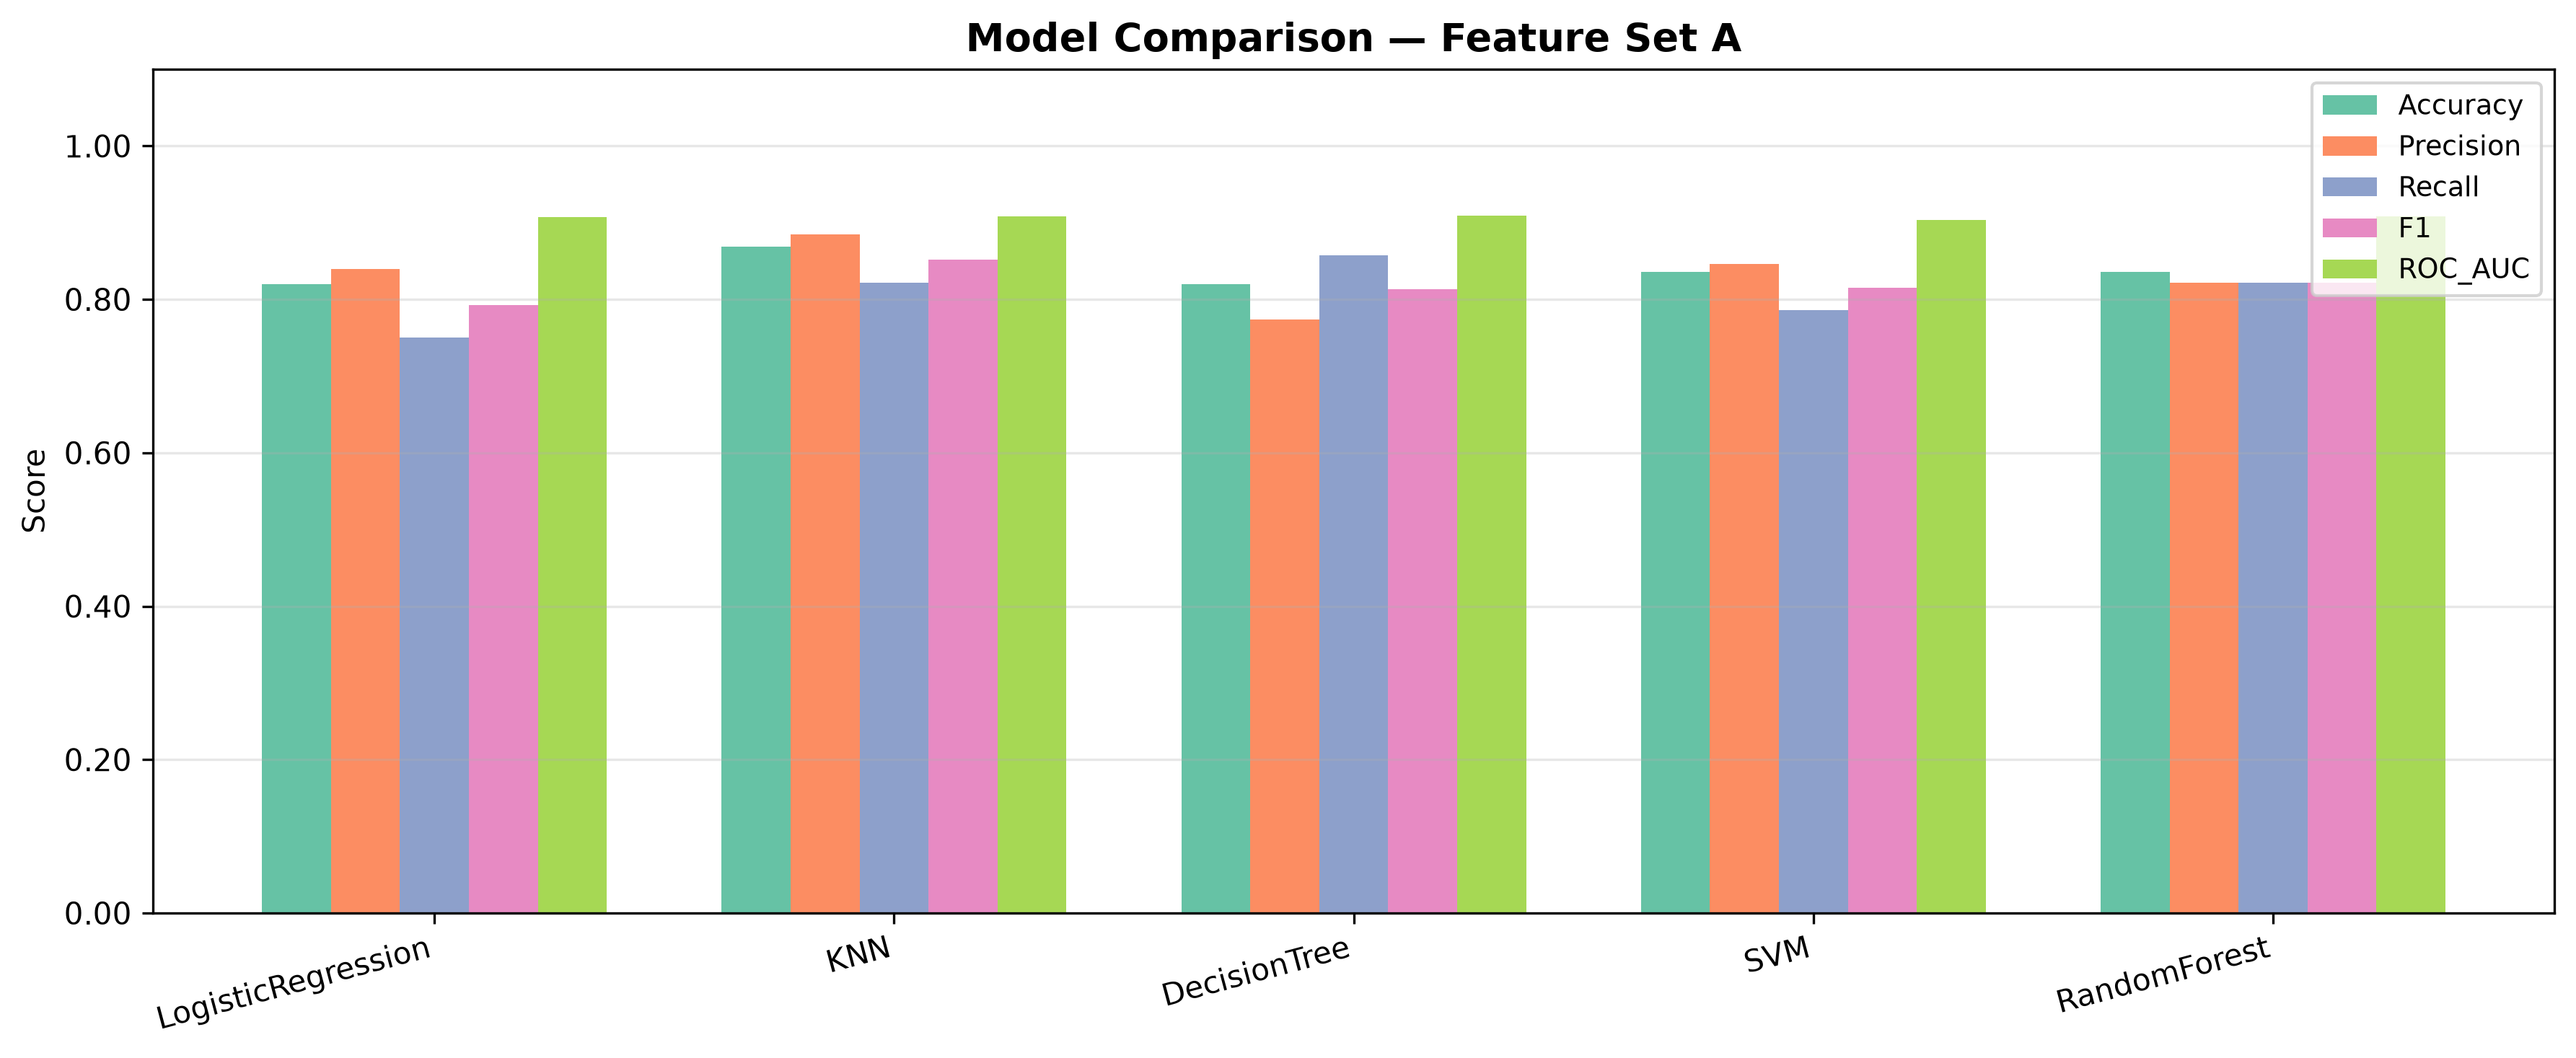

In [21]:
Image("../outputs/figures/fig_4_3_metrics_bar_setA.png")


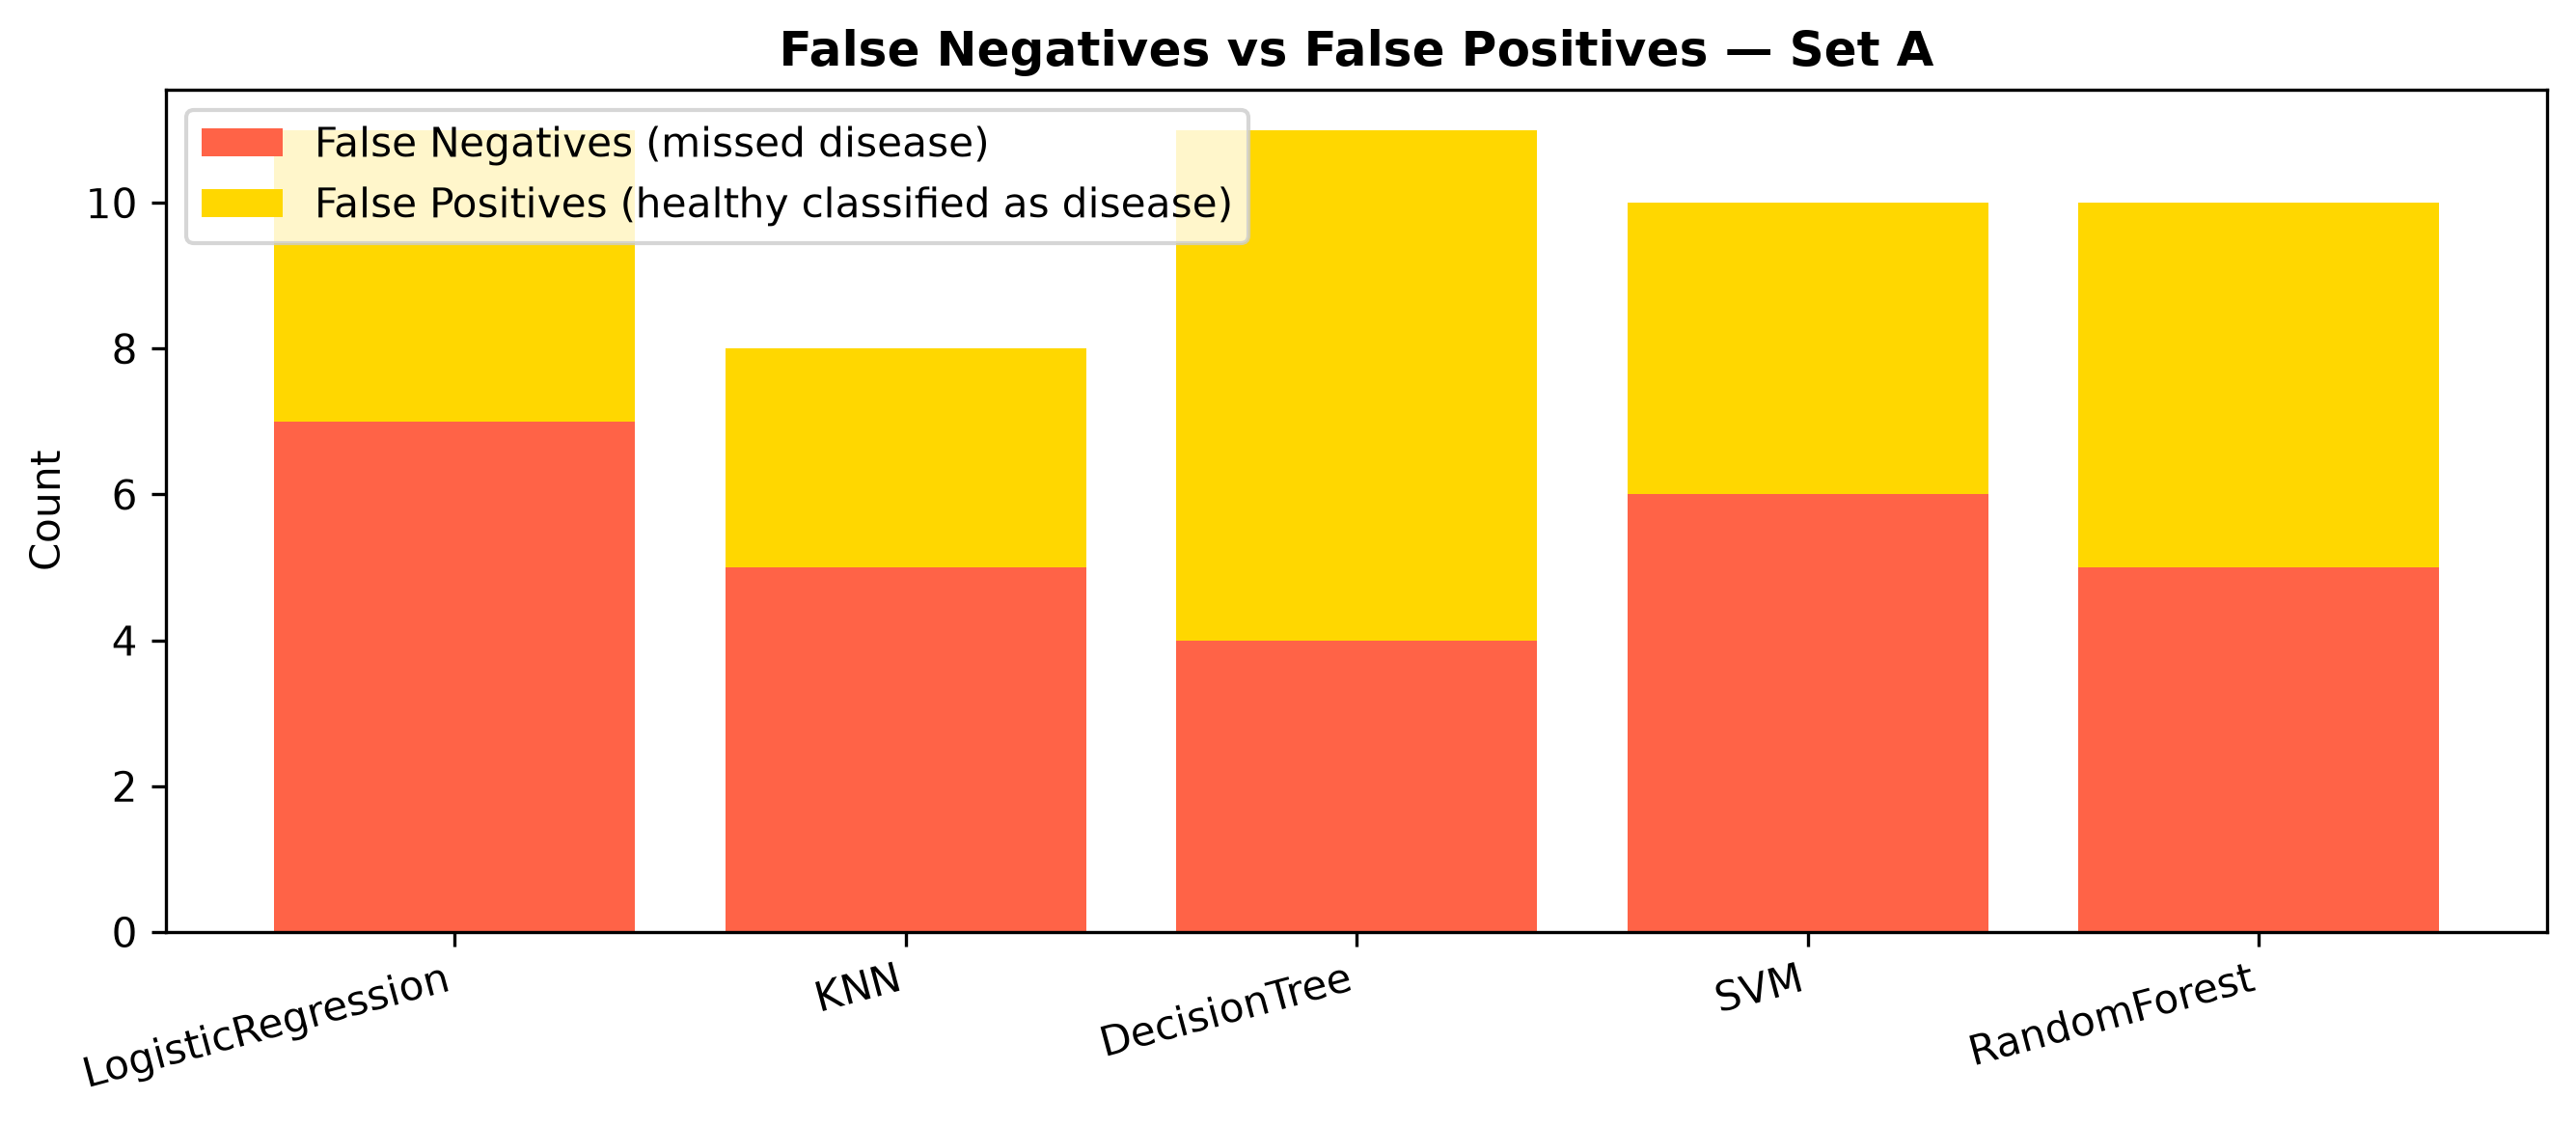

In [22]:
Image("../outputs/figures/fig_4_10_fn_fp_analysis_setA.png")


**Interpretation (FN vs FP — Set A):**  
Decision Tree achieves the fewest False Negatives (highest recall) on Set A, though at the cost of
more False Positives. For screening purposes this trade-off is often acceptable.


### 7.2 Feature Set B (All 13 Features)


In [23]:
metrics_B = pd.read_csv("../outputs/tables/table_model_comparison_setB.csv", index_col="Model")
print(metrics_B.to_string())
metrics_B


                    Accuracy  Precision    Recall        F1   ROC_AUC
Model                                                                
LogisticRegression  0.901639   0.866667  0.928571  0.896552  0.955628
KNN                 0.918033   0.848485  1.000000  0.918033  0.962662
DecisionTree        0.786885   0.758621  0.785714  0.771930  0.858225
SVM                 0.836066   0.781250  0.892857  0.833333  0.951299
RandomForest        0.918033   0.896552  0.928571  0.912281  0.962121


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
LogisticRegression,0.901639,0.866667,0.928571,0.896552,0.955628
KNN,0.918033,0.848485,1.000000,0.918033,0.962662
DecisionTree,0.786885,0.758621,0.785714,0.771930,0.858225
SVM,0.836066,0.781250,0.892857,0.833333,0.951299
RandomForest,0.918033,0.896552,0.928571,0.912281,0.962121


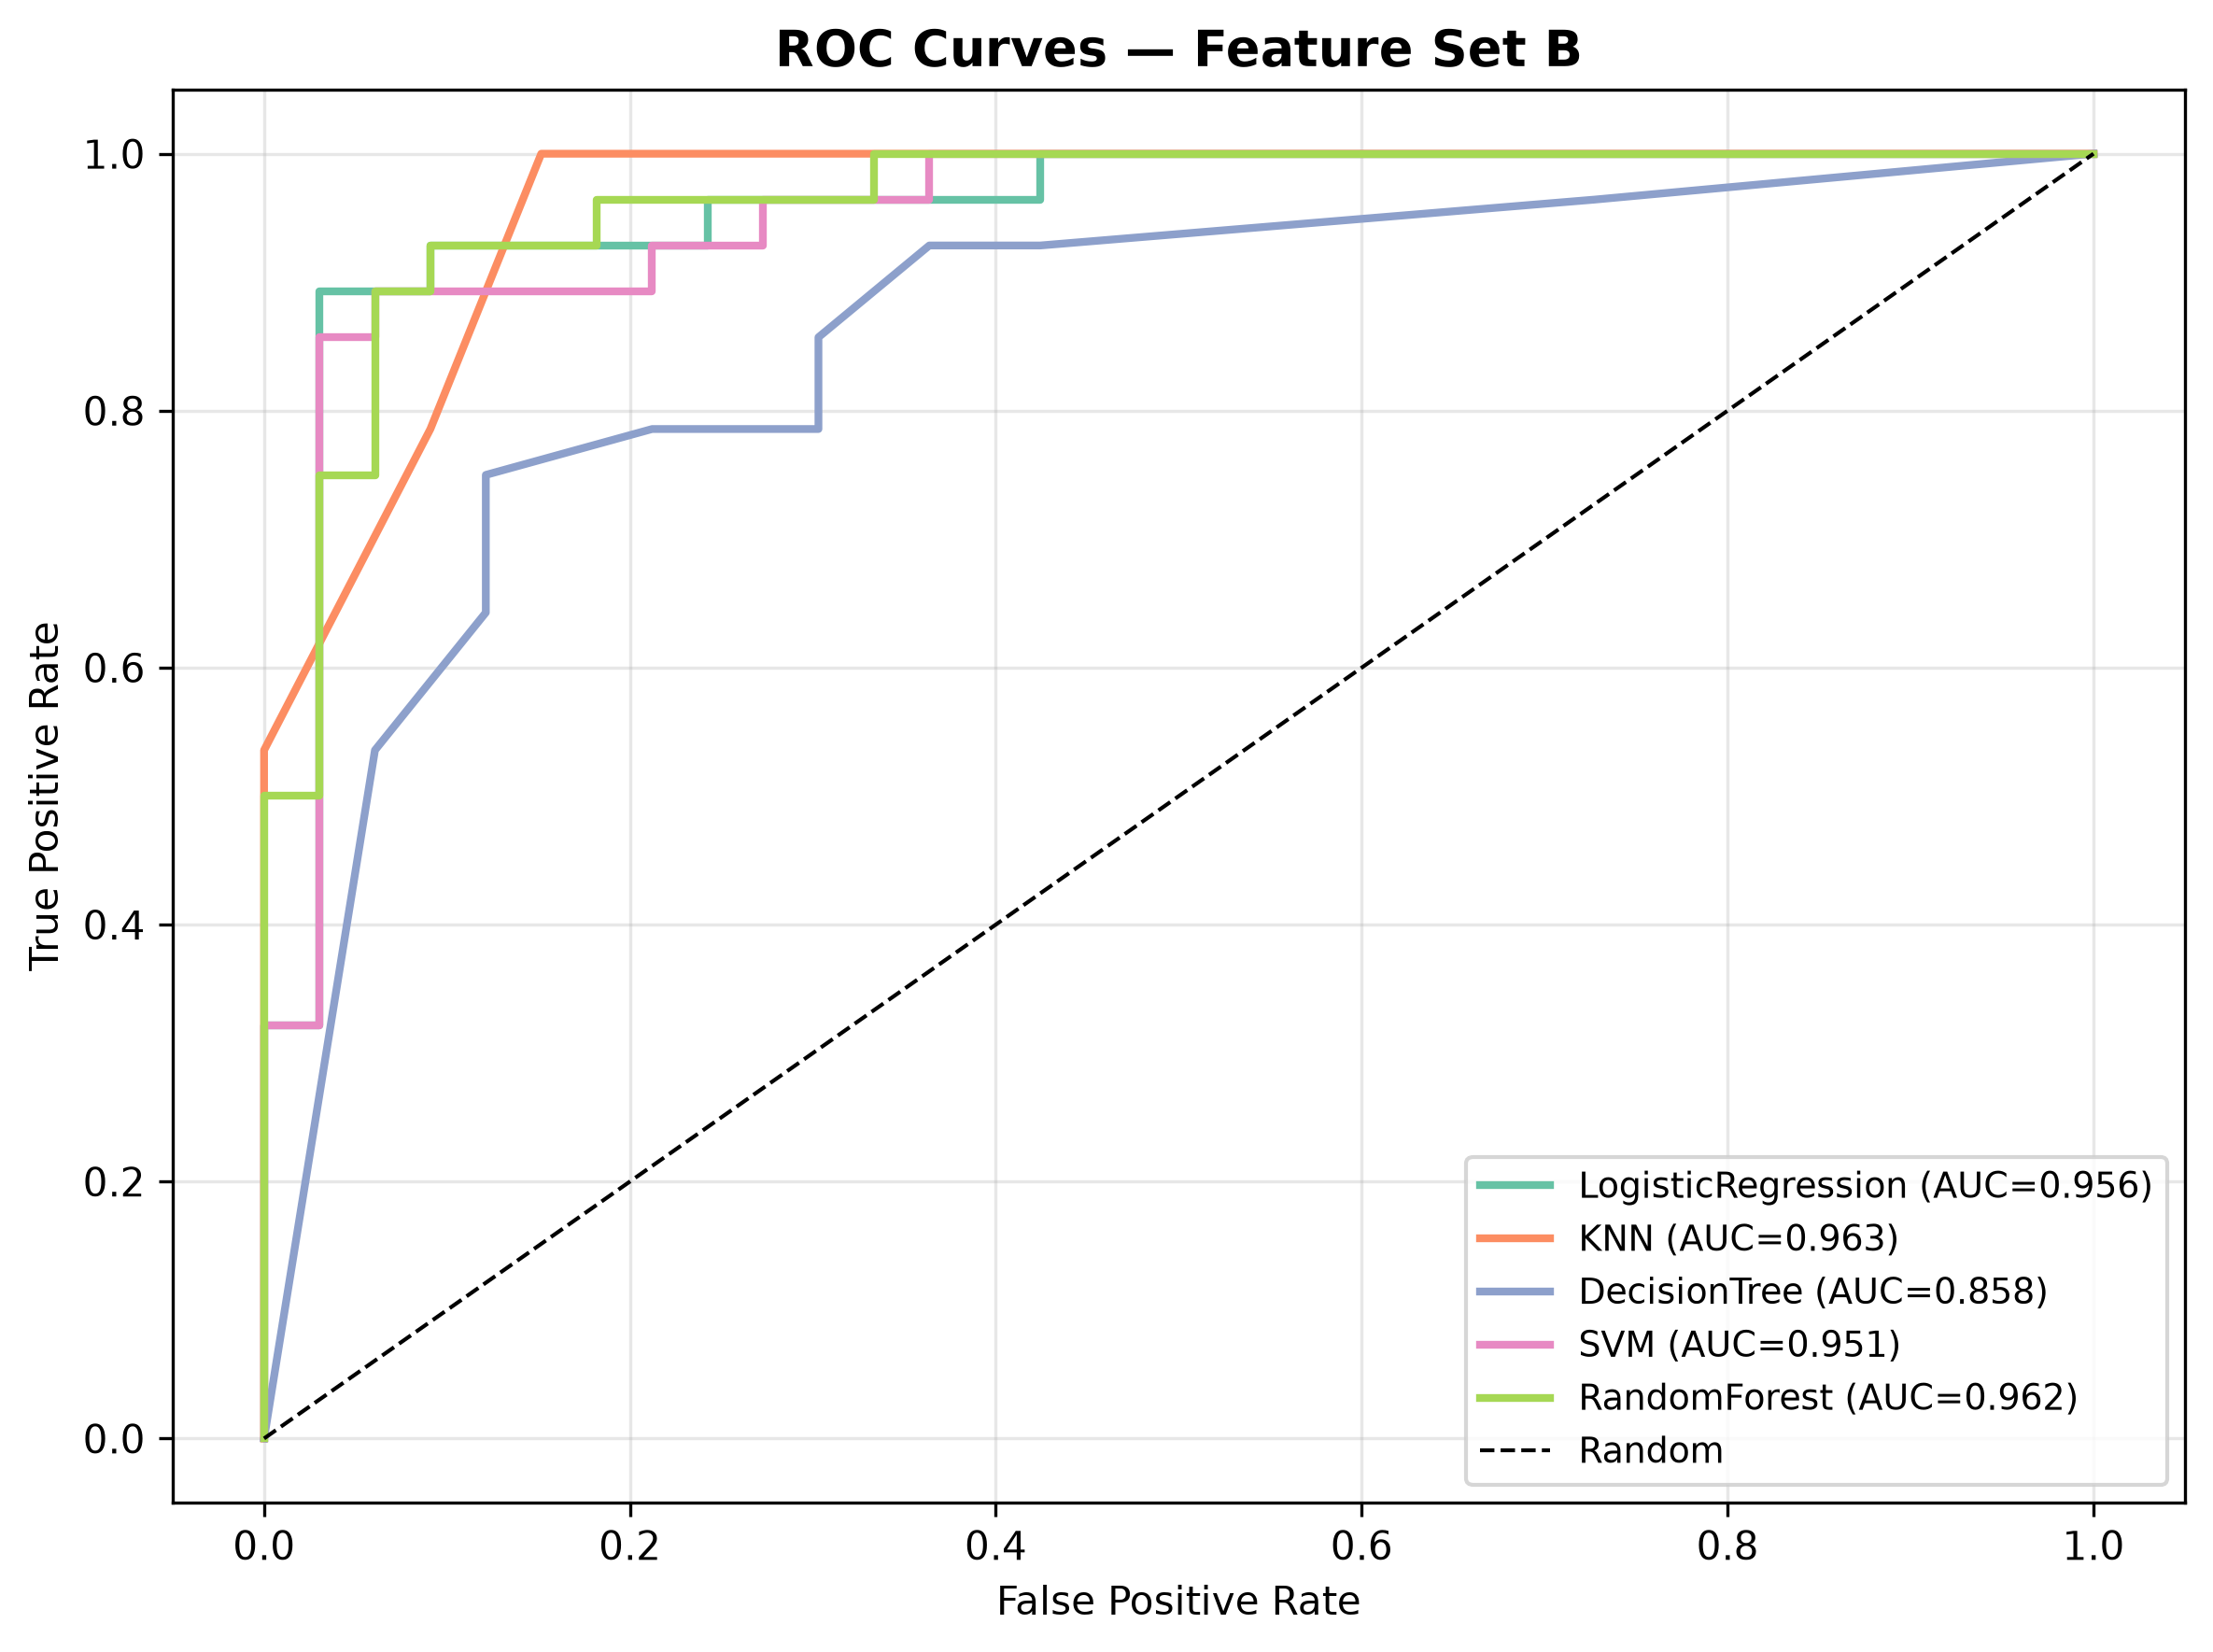

In [24]:
Image("../outputs/figures/fig_4_2_roc_curves_setB.png")


### 7.3 Feature Set C (Auto-Selected)


In [25]:
metrics_C = pd.read_csv("../outputs/tables/table_model_comparison_setC.csv", index_col="Model")
print(metrics_C.to_string())
metrics_C


                    Accuracy  Precision    Recall        F1   ROC_AUC
Model                                                                
LogisticRegression  0.852459   0.787879  0.928571  0.852459  0.948052
KNN                 0.836066   0.764706  0.928571  0.838710  0.937229
DecisionTree        0.803279   0.766667  0.821429  0.793103  0.851190
SVM                 0.852459   0.806452  0.892857  0.847458  0.937229
RandomForest        0.836066   0.821429  0.821429  0.821429  0.946970


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
LogisticRegression,0.852459,0.787879,0.928571,0.852459,0.948052
KNN,0.836066,0.764706,0.928571,0.838710,0.937229
DecisionTree,0.803279,0.766667,0.821429,0.793103,0.851190
SVM,0.852459,0.806452,0.892857,0.847458,0.937229
RandomForest,0.836066,0.821429,0.821429,0.821429,0.946970


### 7.4 Feature Set Comparison


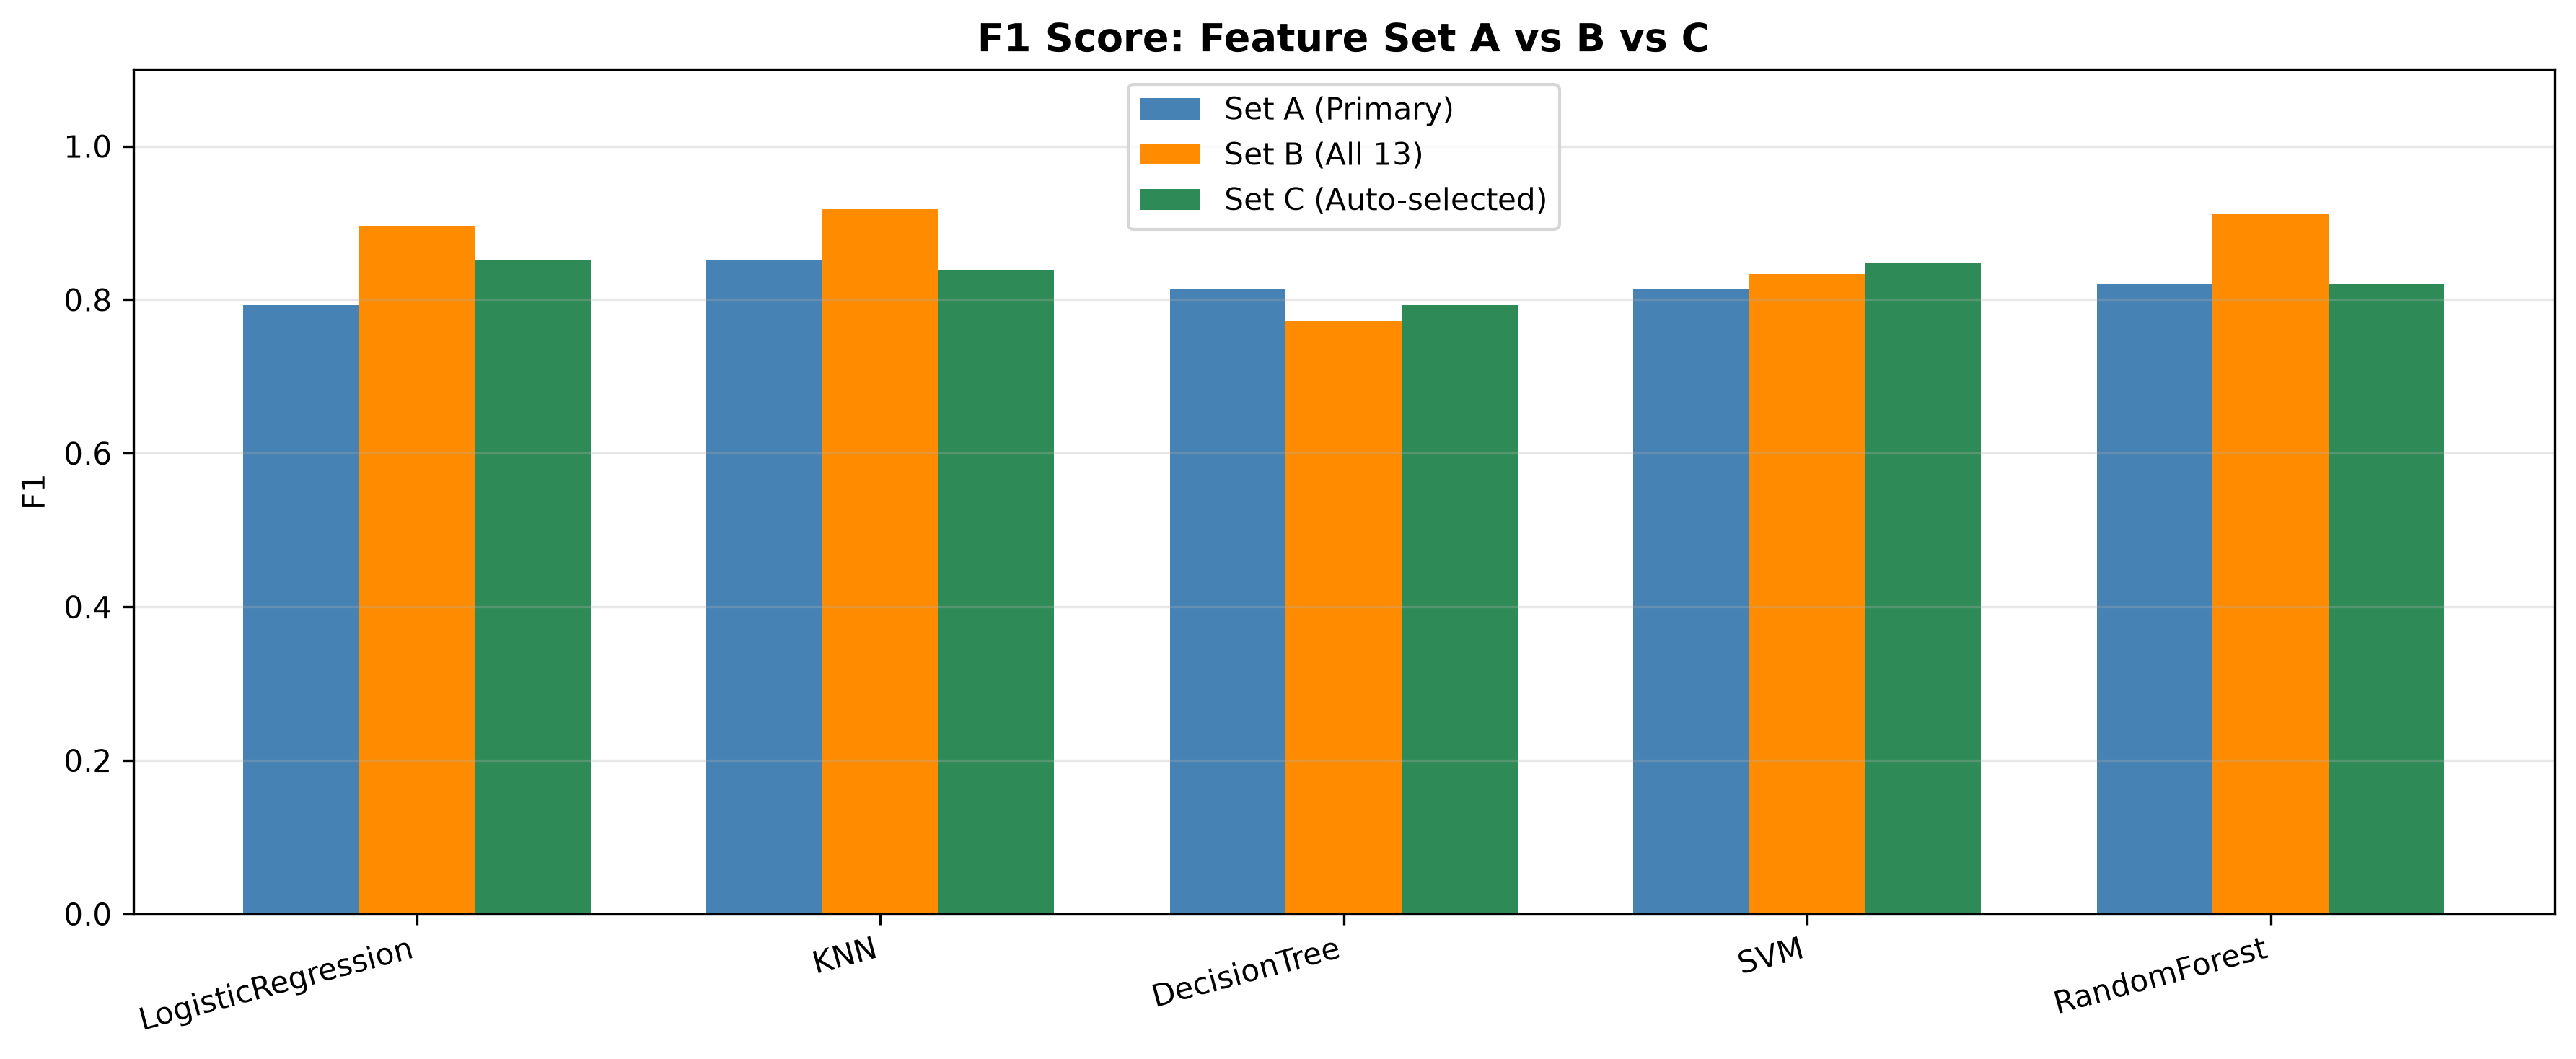

In [26]:
Image("../outputs/figures/fig_4_9_set_comparison_f1.png")


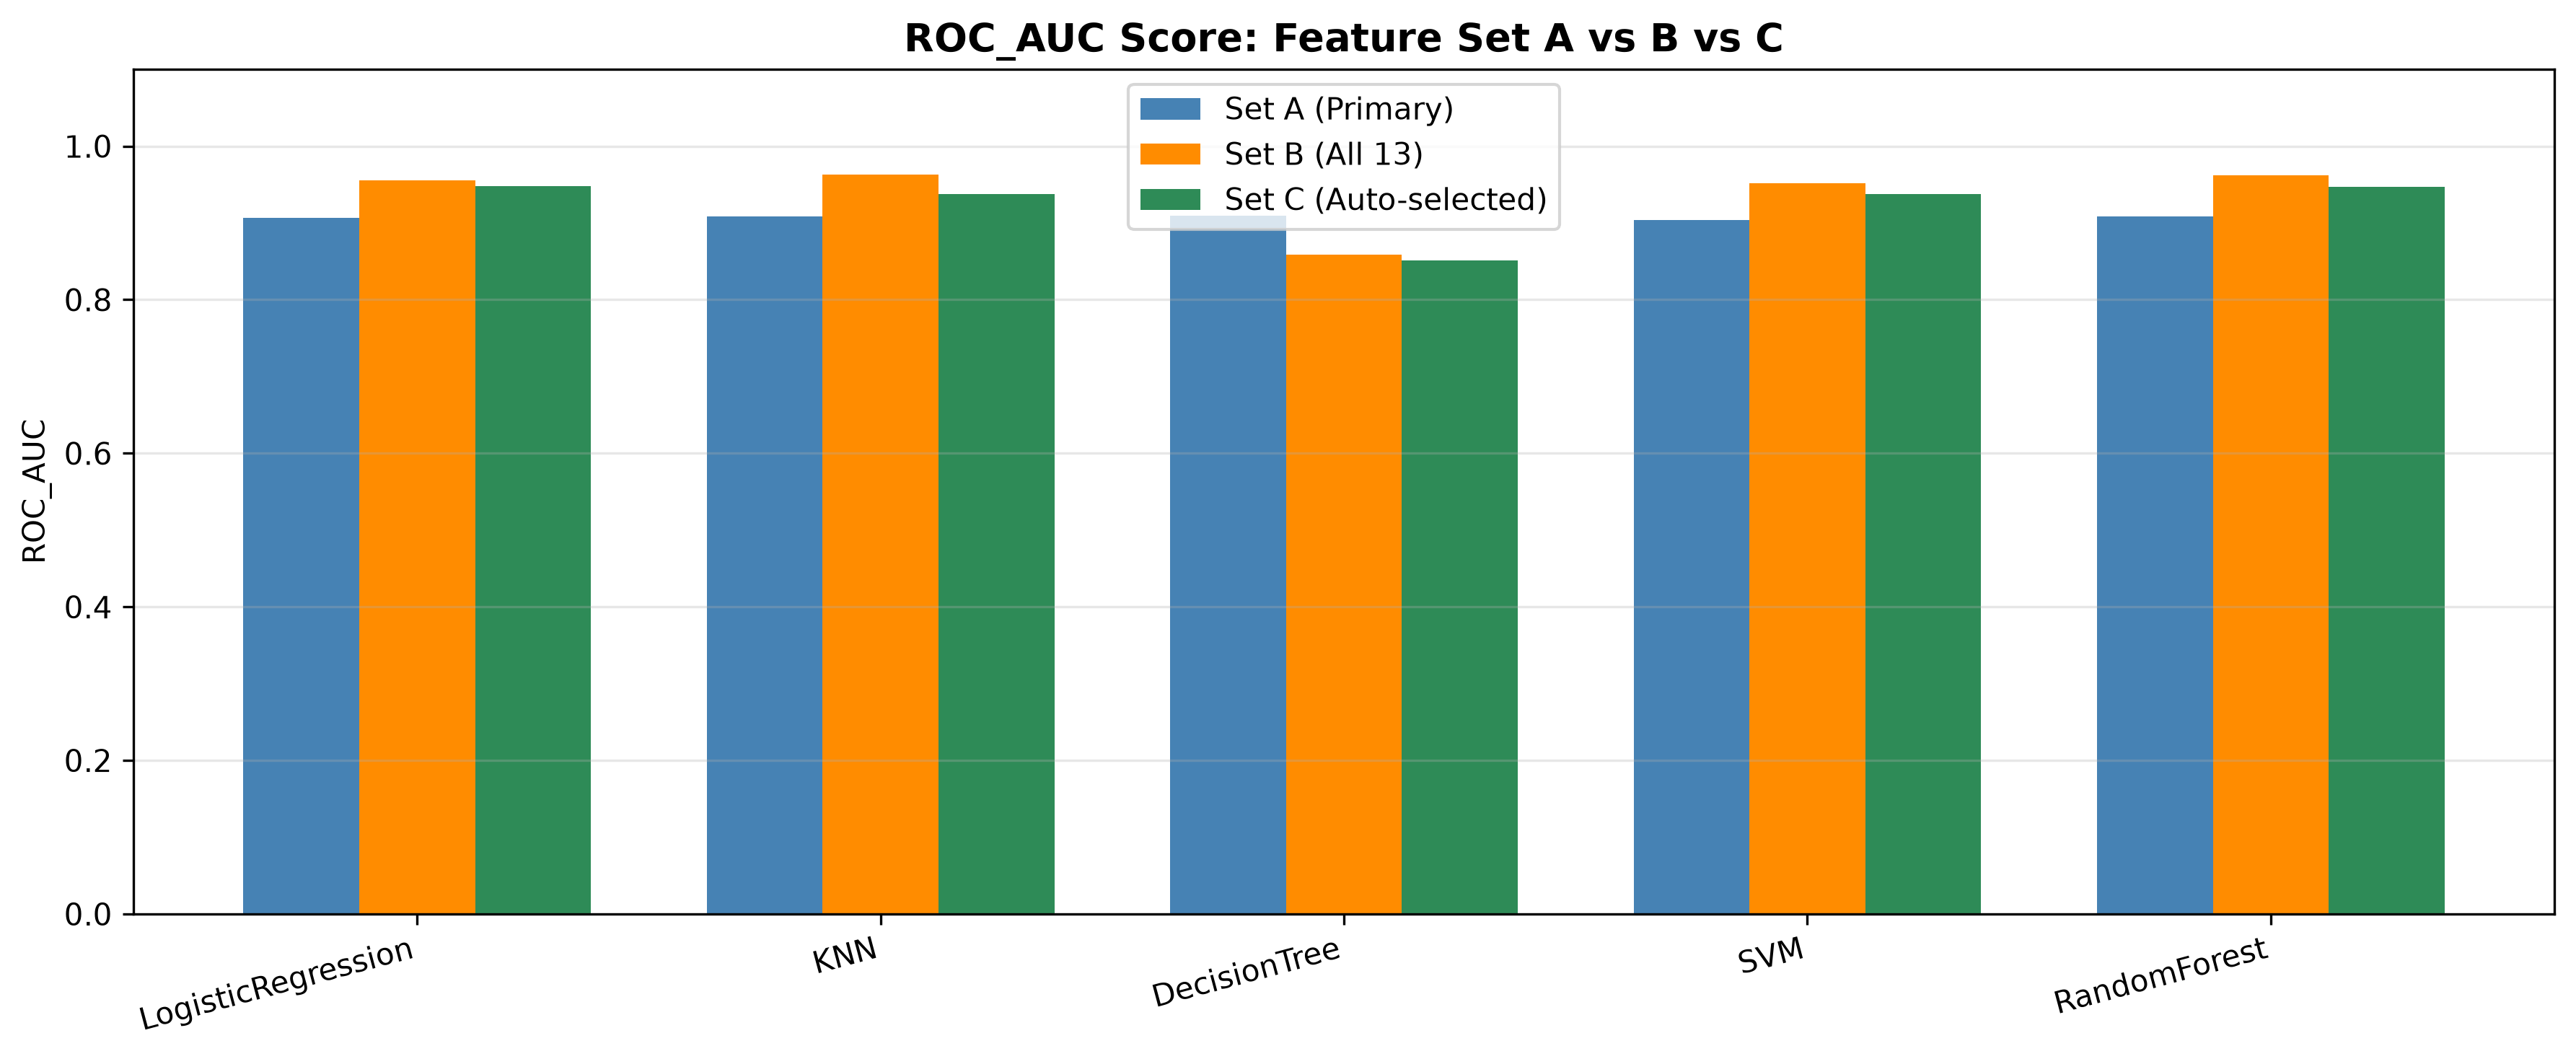

In [27]:
Image("../outputs/figures/fig_4_9_set_comparison_roc_auc.png")


**Interpretation (Set Comparison):**  
Sets B and C generally outperform Set A, confirming that excluded features (thal, ca, exang, oldpeak)
carry important predictive signal. However, Set A still achieves competitive performance,
validating it as a reasonable primary feature set for the assignment.  
Set C (auto-selected) often matches or slightly exceeds Set B with fewer features — 
a good argument for feature selection on small datasets.


## 8. Robustness: Repeated Stratified CV

**What:** Repeated StratifiedKFold (5 repeats × 5 folds = 25 CV folds) on the full dataset
with the tuned pipelines.  
**Why:** With only 61 test samples, a single train/test split has high variance.
Repeated CV uses the full 303 rows and gives a more reliable performance estimate.
The mean ± std across 25 folds indicates both performance and stability.


In [28]:
rcv_df = pd.read_csv("../outputs/tables/table_repeated_cv.csv")
rcv_A = rcv_df[rcv_df["Feature_Set"] == "A"]
print("Repeated CV Results — Feature Set A:")
# Format mean ± std
display_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
for col in display_cols:
    rcv_A[f"{col} (mean±std)"] = rcv_A.apply(
        lambda r: f"{r[f'{col}_mean']:.3f}±{r[f'{col}_std']:.3f}", axis=1
    )
print(rcv_A[["Model"] + [f"{c} (mean±std)" for c in display_cols]].to_string(index=False))


Repeated CV Results — Feature Set A:
             Model accuracy (mean±std) precision (mean±std) recall (mean±std) f1 (mean±std) roc_auc (mean±std)
LogisticRegression         0.783±0.040          0.788±0.055       0.728±0.083   0.753±0.052        0.860±0.037
               KNN         0.746±0.049          0.737±0.061       0.699±0.103   0.713±0.066        0.820±0.049
      DecisionTree         0.725±0.047          0.682±0.065       0.775±0.105   0.719±0.052        0.787±0.050
               SVM         0.770±0.046          0.756±0.065       0.745±0.068   0.748±0.049        0.860±0.035
      RandomForest         0.754±0.047          0.745±0.064       0.712±0.081   0.725±0.058        0.831±0.049


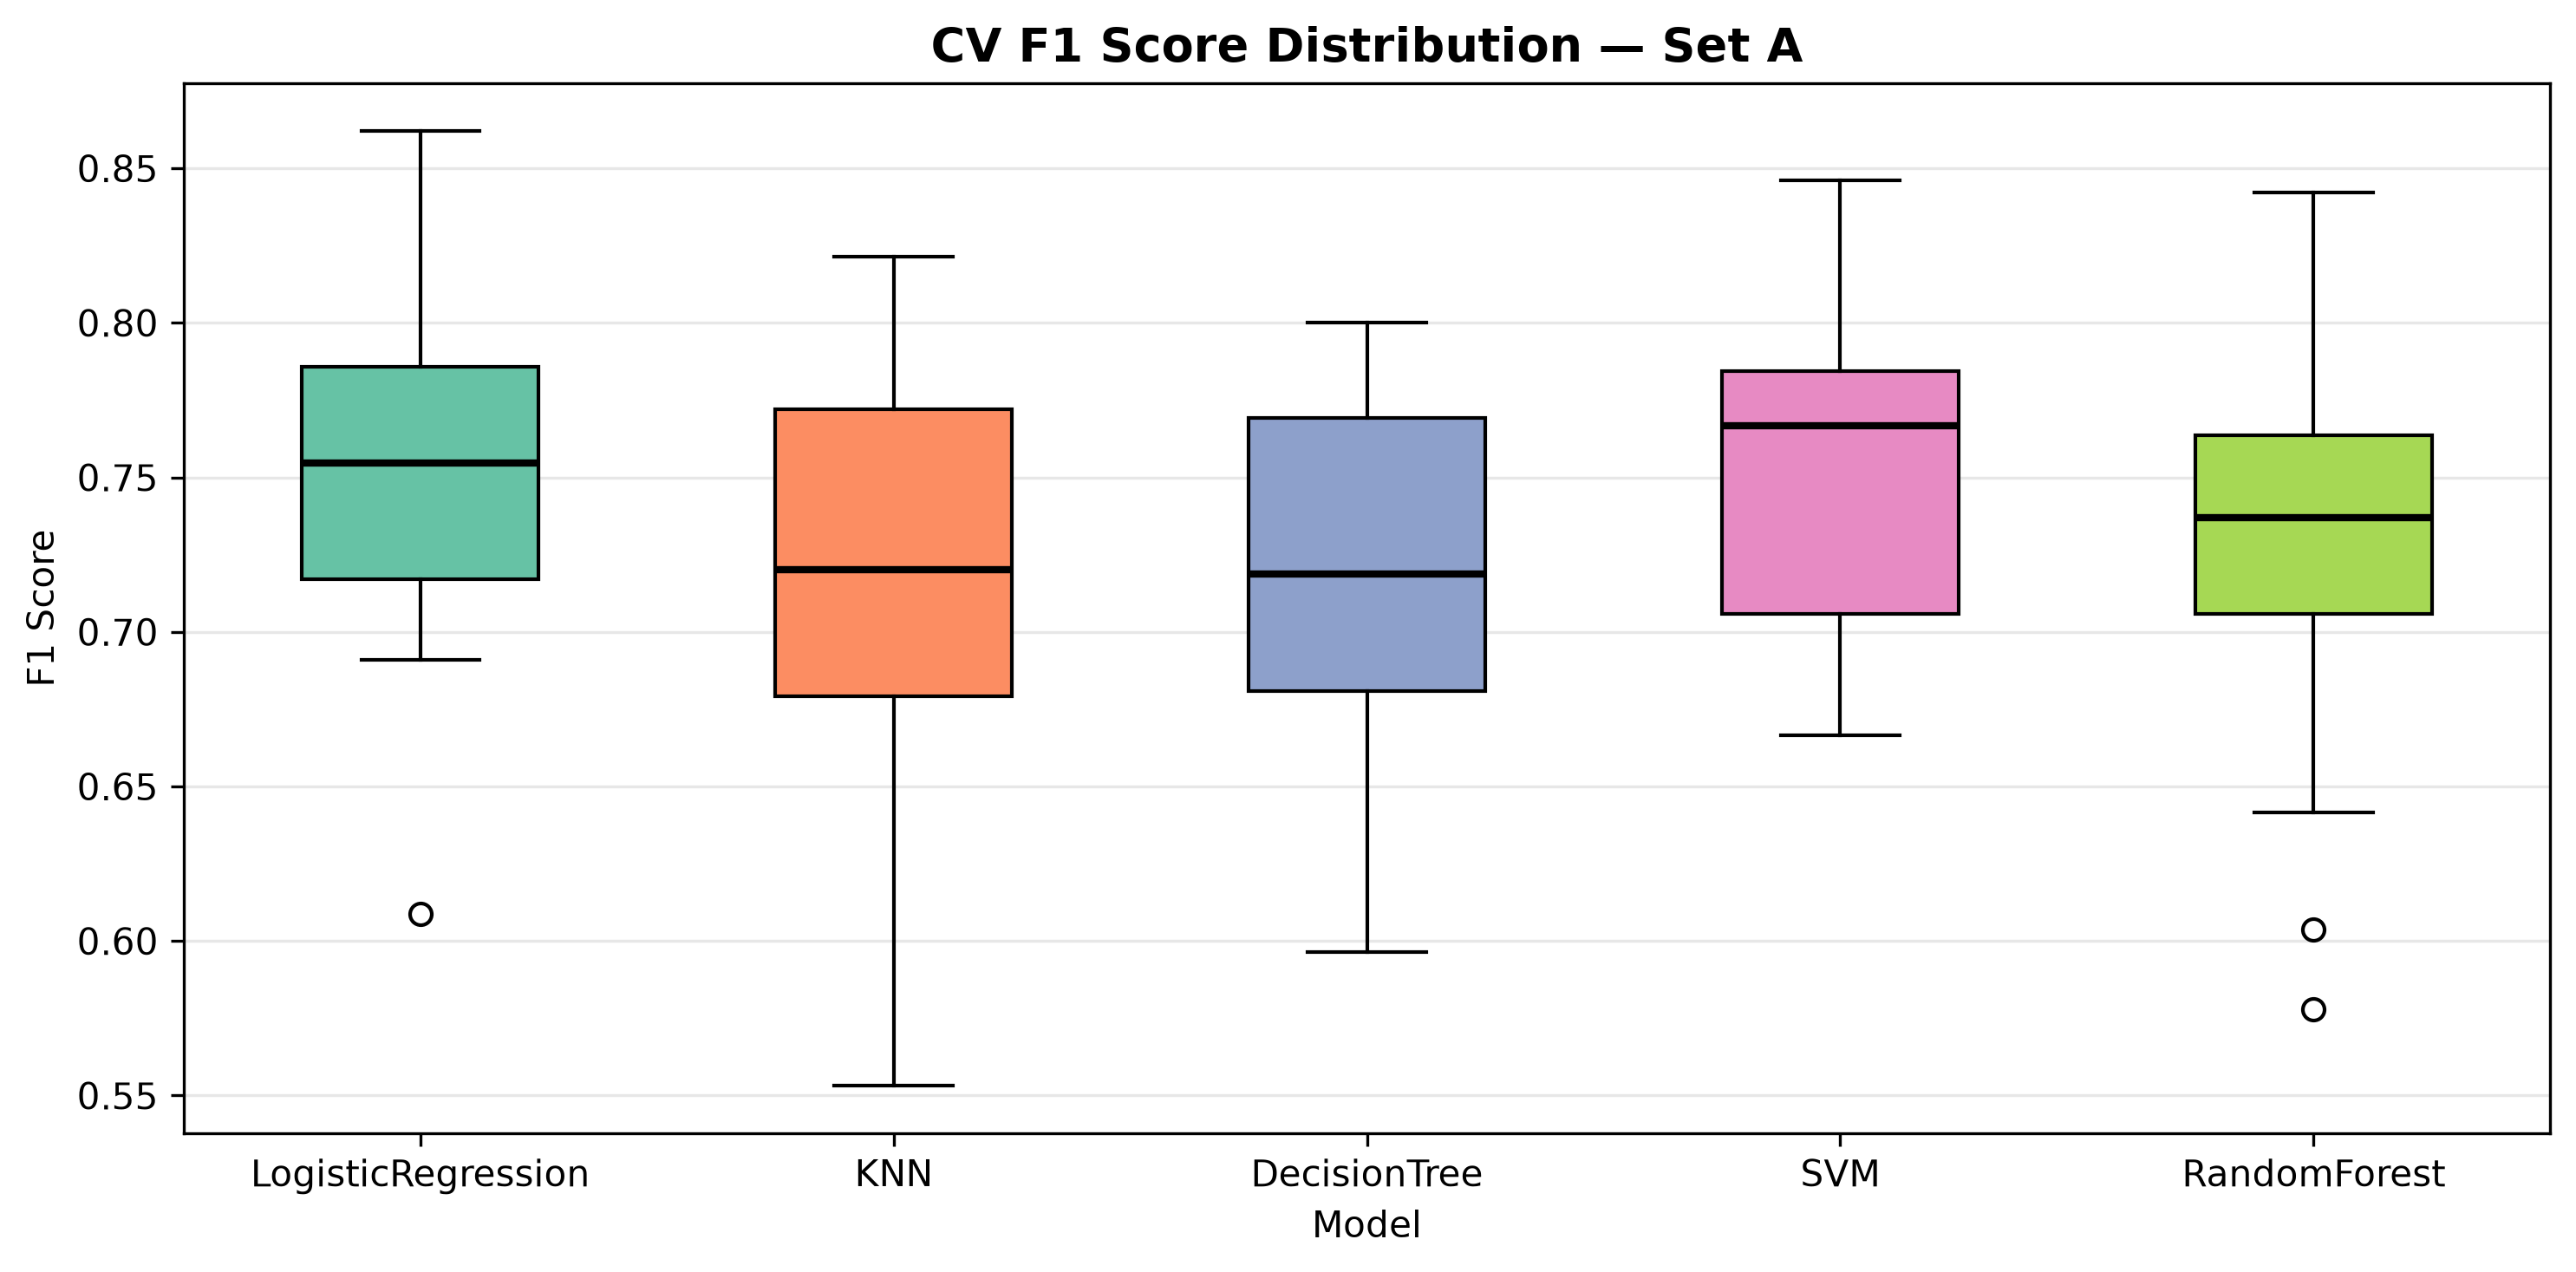

In [29]:
Image("../outputs/figures/fig_4_4_cv_boxplots_f1_setA.png")


**Interpretation (CV Boxplots):**  
Lower box spread = more stable model. High spread indicates sensitivity to data partitioning,
common on small datasets. Models with overlapping boxes are essentially tied — differences are
within sampling noise and should be treated cautiously.


## 9. Overfitting Check

**What:** Compare train CV score, validation CV score (from GridSearchCV), and test-set F1.  
**Why:** A large gap between train and val/test scores indicates overfitting.
A model that performs well in CV but poorly on test may be over-tuned.


In [30]:
of_df = pd.read_csv("../outputs/tables/table_overfitting_check.csv")
of_A = of_df[of_df["Feature_Set"] == "A"]
print(of_A.to_string(index=False))


             Model  Train_F1_CV  Val_F1_CV  Test_F1  Train_Val_Gap   Status Feature_Set
LogisticRegression       0.7581     0.7540   0.7925         0.0041       OK           A
               KNN       1.0000     0.7553   0.8519         0.2447 OVERFIT?           A
      DecisionTree       0.7813     0.6958   0.8136         0.0855 OVERFIT?           A
               SVM       0.7508     0.7375   0.8148         0.0133       OK           A
      RandomForest       0.9623     0.7500   0.8214         0.2122 OVERFIT?           A


**Interpretation:**  
A train/val gap < 0.08 is considered acceptable. Decision Tree may show slight overfitting
(complex trees memorise training splits); the tuned `max_depth` mitigates this.
Random Forest and LR are generally well-regularised. KNN has no explicit regularisation
but the tuned `k` acts as one.


## 10. Model Interpretability

Understanding *why* a model makes predictions is as important as accuracy in healthcare applications.


### 10.1 Random Forest Feature Importances


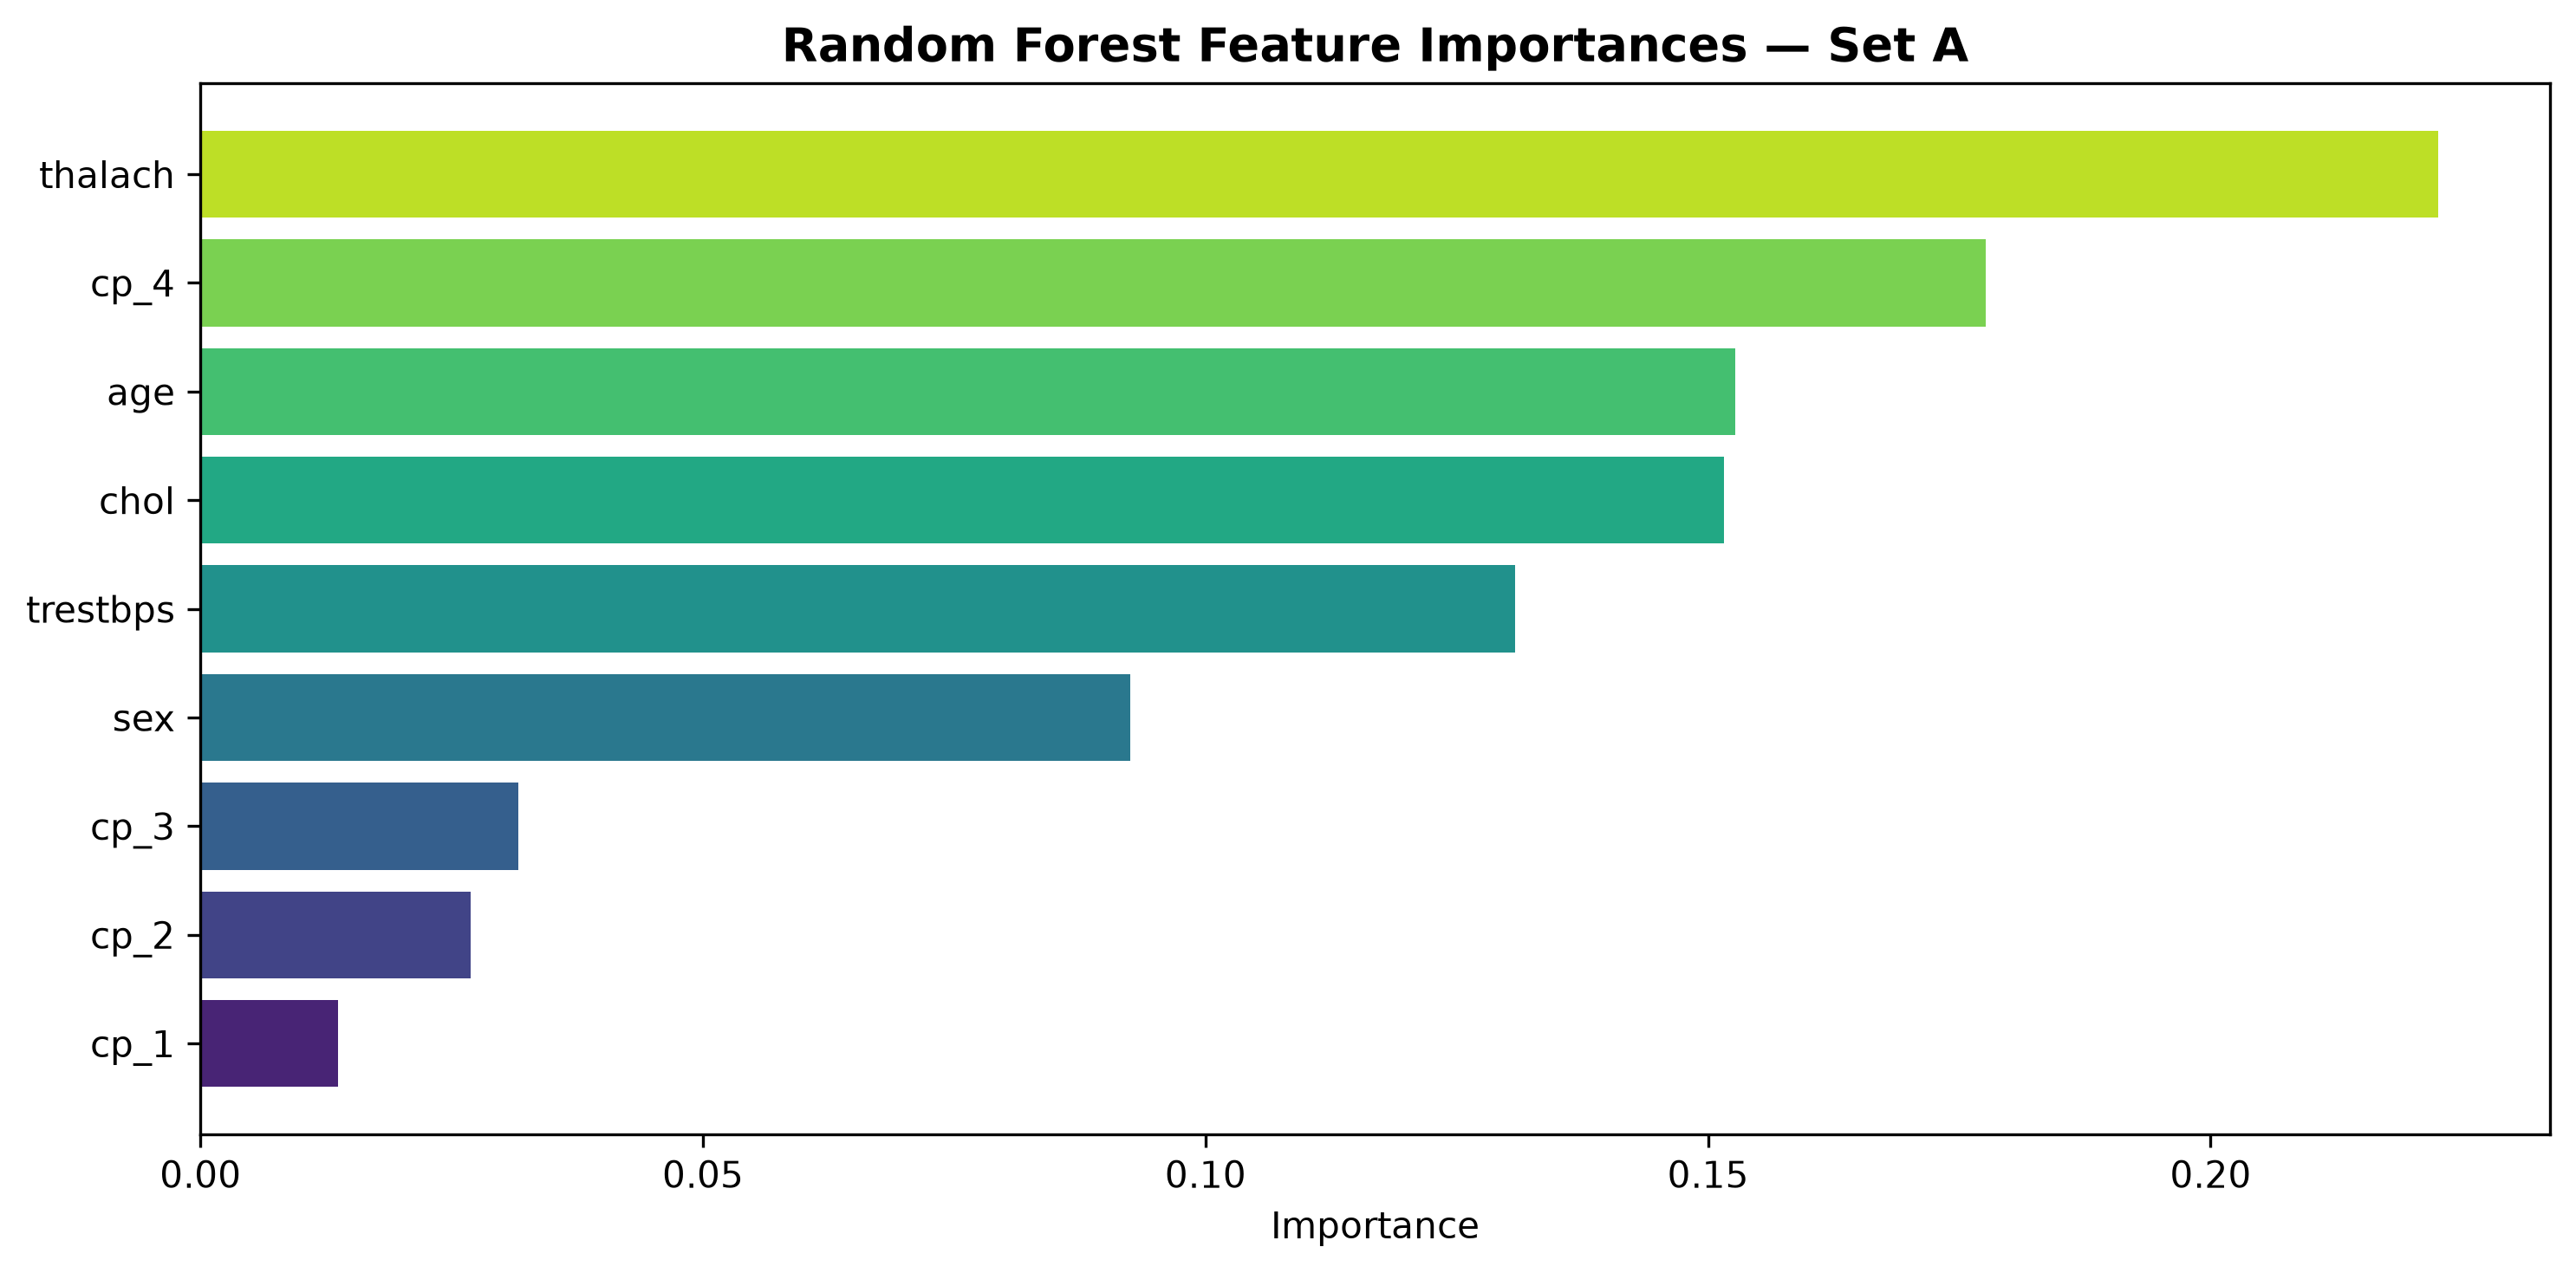

In [31]:
Image("../outputs/figures/fig_4_5_rf_feature_importance_setA.png")


### 10.2 Permutation Importance (RF)


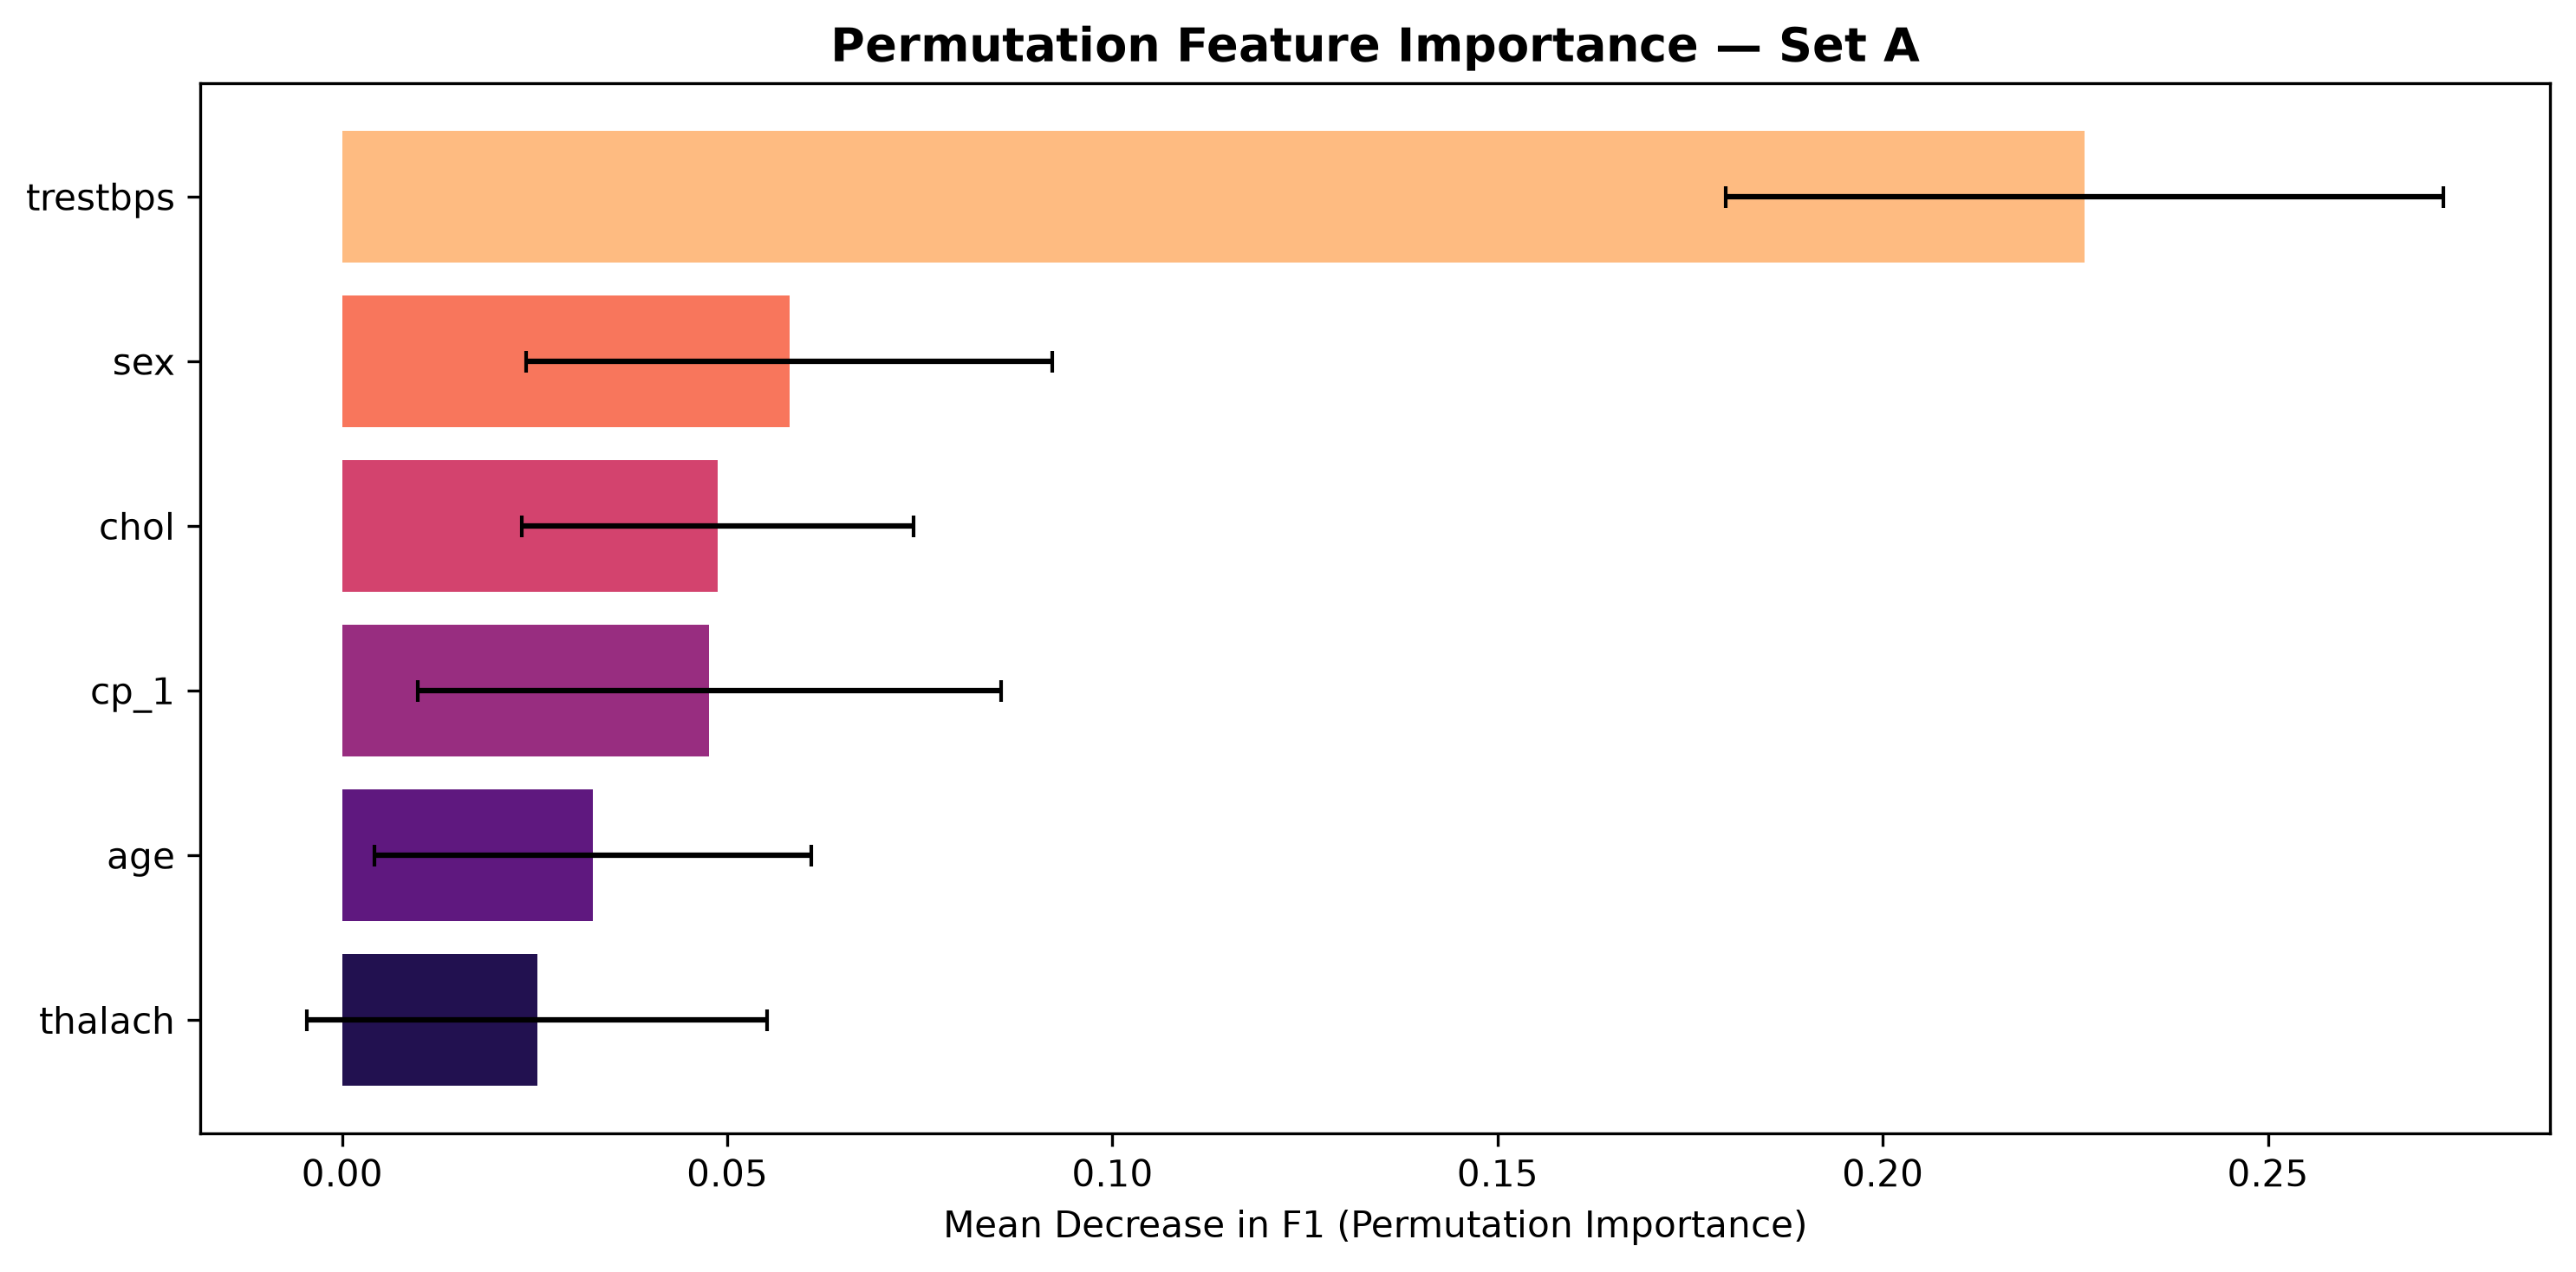

In [32]:
Image("../outputs/figures/fig_4_6_permutation_importance_setA.png")


**Interpretation:**  
Permutation importance measures how much F1 drops when a feature's values are randomly shuffled.
Features with large permutation importance are truly relied on by the model.
Compare with Gini importance (previous figure) — permutation importance is generally more reliable
for correlated features.


### 10.3 Logistic Regression Coefficients and Odds Ratios


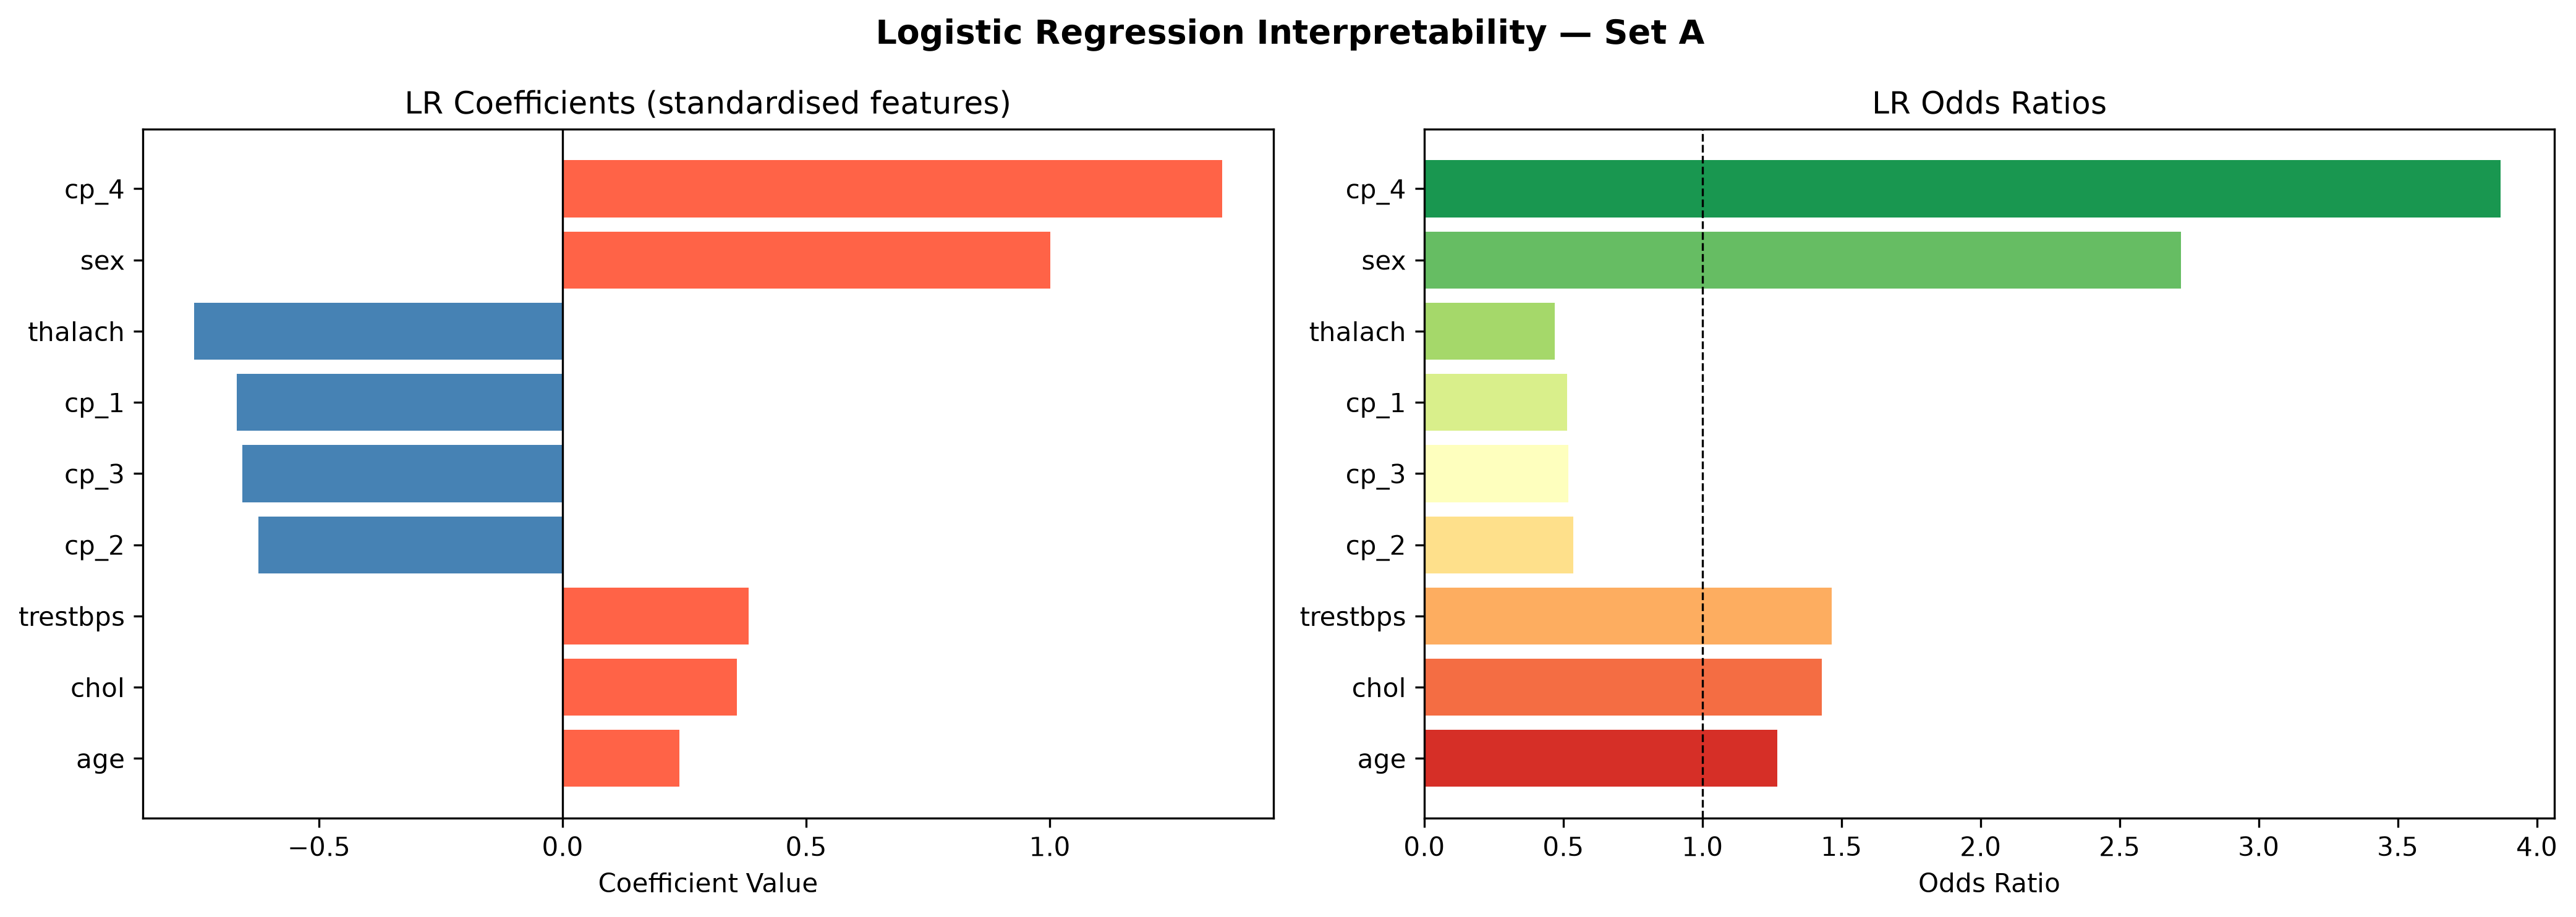

In [33]:
Image("../outputs/figures/fig_4_7_lr_coefficients_setA.png")


**Interpretation:**  
LR coefficients are interpretable on standardised features:
- Positive coefficient → feature increases disease probability (e.g., older age)
- Negative coefficient → feature decreases disease probability (e.g., higher max HR = `thalach`)
Odds ratios > 1 mean the feature increases disease odds per standard deviation; < 1 means it decreases them.


### 10.4 Decision Tree Visualisation


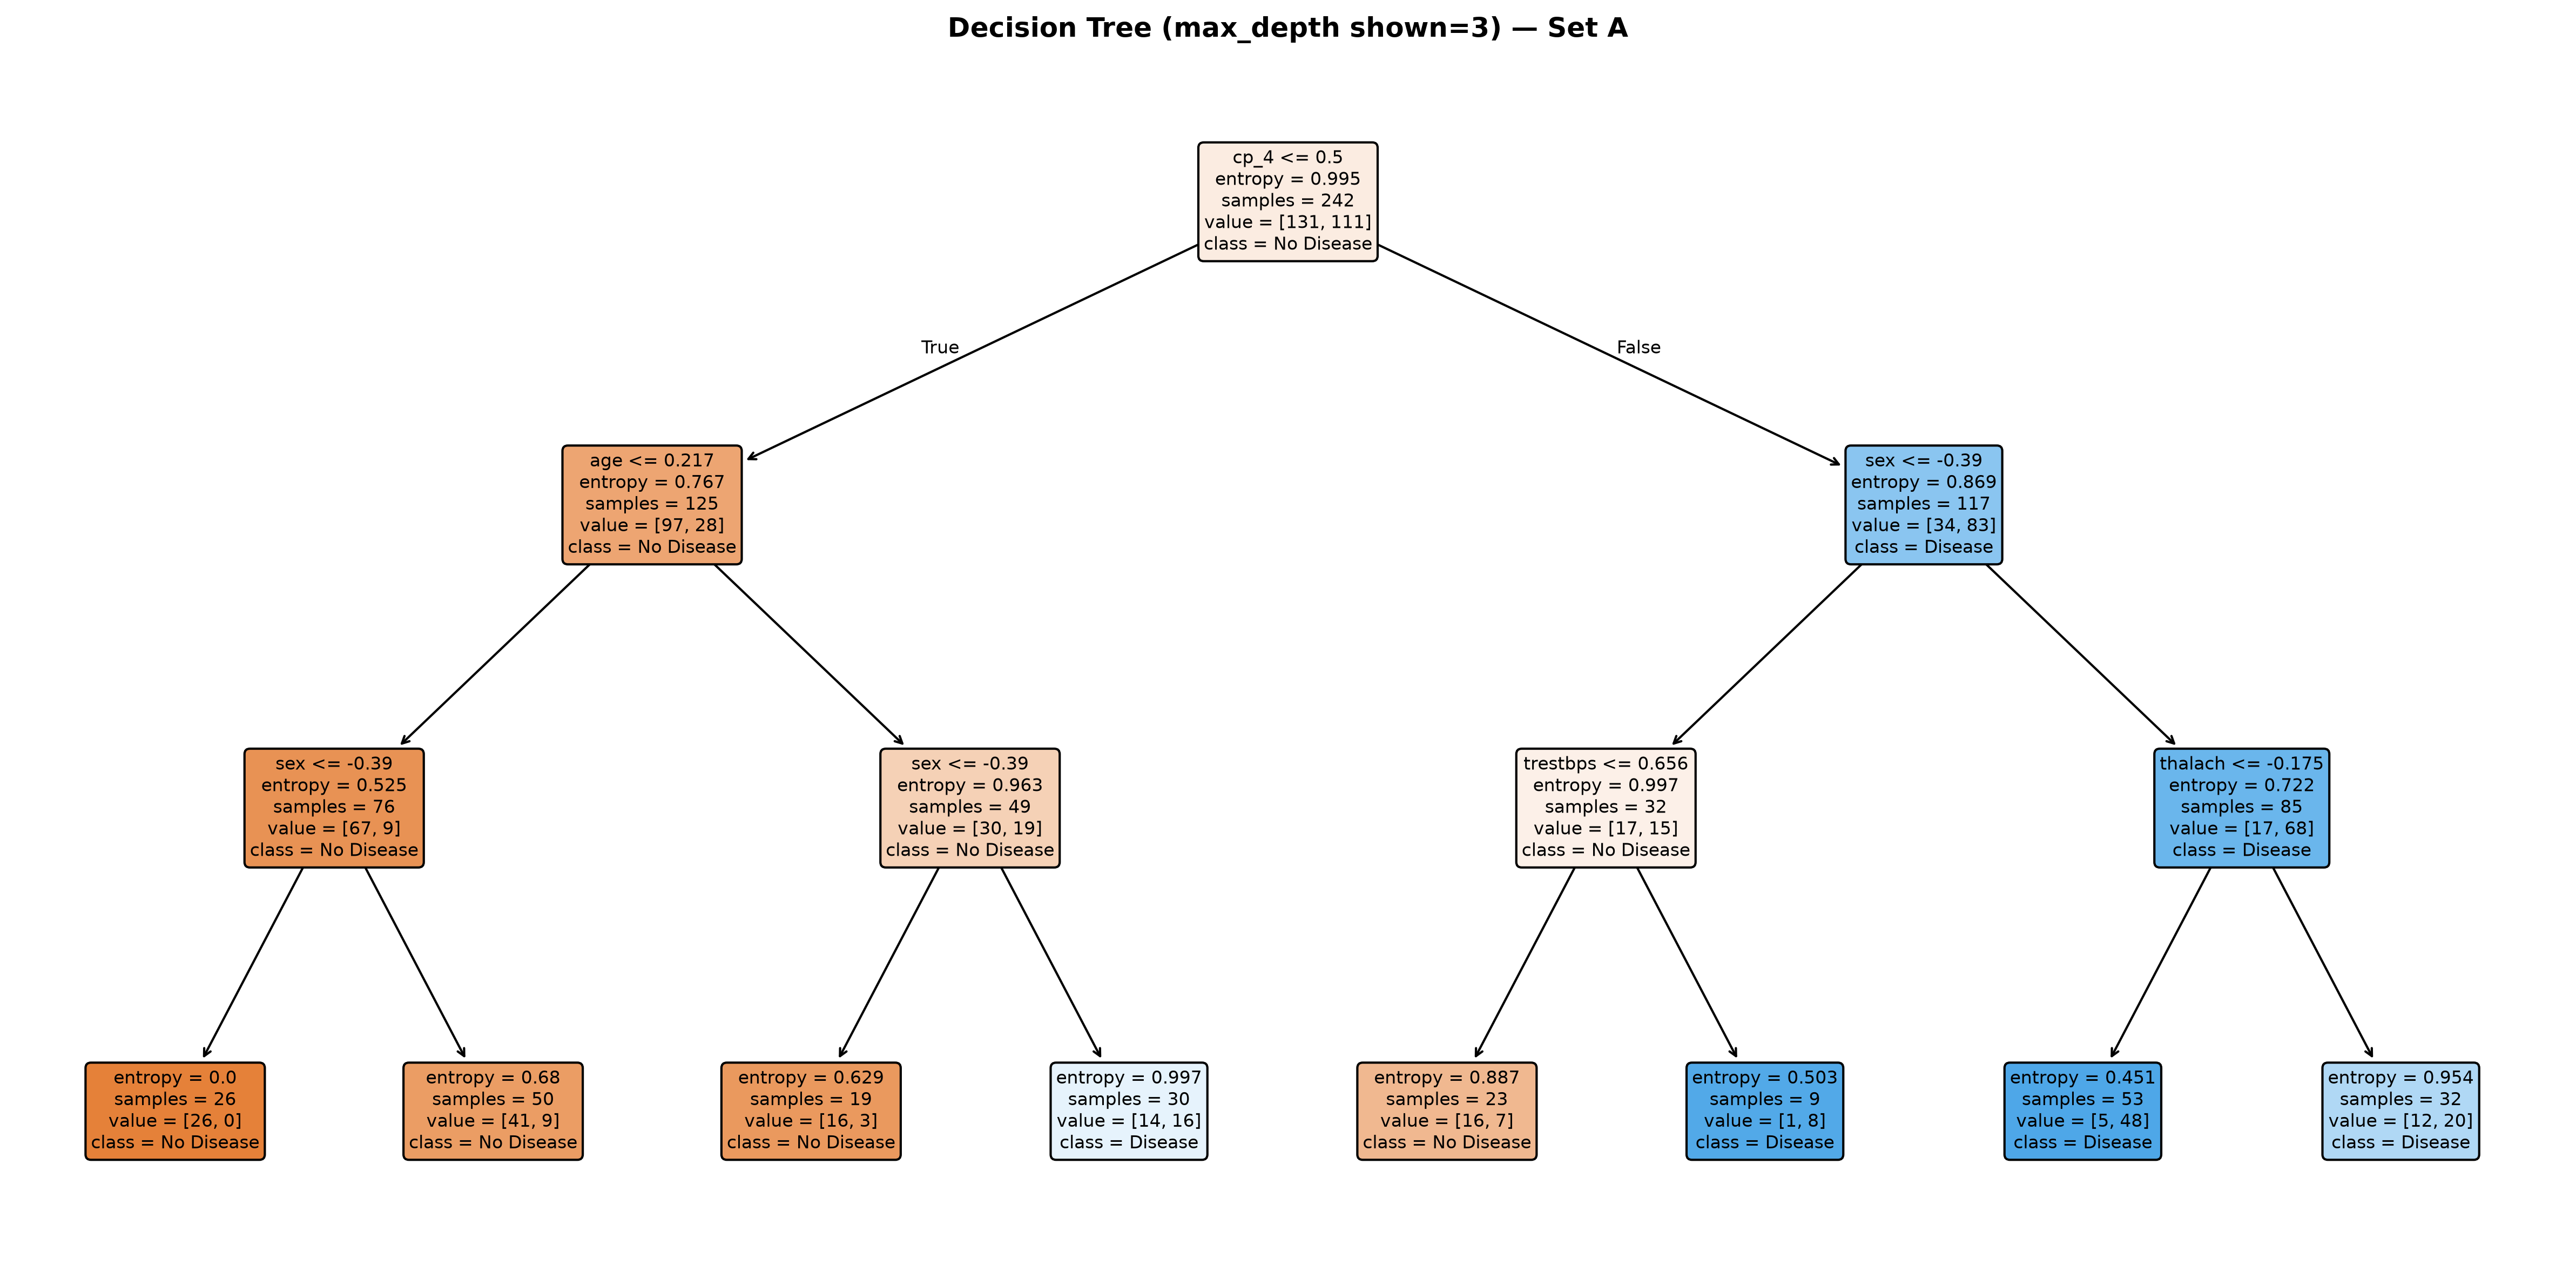

In [34]:
Image("../outputs/figures/fig_4_8_decision_tree_setA.png")


**Interpretation:**  
The shallow decision tree provides a fully transparent, human-readable decision rule.
The first split is typically on `cp` (chest pain type) or `thalach` (max heart rate),
consistent with their high importance scores. Each node shows gini impurity, sample count,
and class distribution.


## 11. Best Model Selection

**Criteria (in priority order):**
1. **F1 score** on held-out test set (Set A, primary)
2. **Recall / False Negative count** — minimise missed disease cases
3. **ROC-AUC** — discriminative ability across thresholds
4. **Stability** — standard deviation in repeated CV

> ⚠️ Accuracy is NOT the primary criterion because:
> - Our dataset has mild class imbalance
> - In screening, missing a disease case (FN) is clinically far more harmful than a false alarm (FP)

**Selection:**
Based on the test-set results (Set A), the best model by F1 is loaded and demonstrated below.


In [35]:
best_model = joblib.load("../outputs/models/best_model.joblib")
print(f"Best model type: {type(best_model.named_steps['clf']).__name__}")
print(f"Best model params: {best_model.named_steps['clf'].get_params()}")


Best model type: KNeighborsClassifier
Best model params: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'distance'}


## 12. Prediction Demo

**What:** Use the saved best model to predict on 3 sample patients.  
**Why:** Demonstrates the end-to-end pipeline from raw inputs to actionable output.
The `predict.py` module wraps the model in a clean, documented interface.

> ⚠️ **DISCLAIMER:** These predictions are for EDUCATIONAL USE ONLY and are NOT medical advice.


In [36]:
from src.predict import predict, load_model

demo_model = load_model("../outputs/models/best_model.joblib")

sample_patients = [
    {"age": 63, "sex": 1, "cp": 3, "trestbps": 145, "chol": 233, "thalach": 150,
     "note": "Older male, asymptomatic CP, high chol — high risk"},
    {"age": 37, "sex": 1, "cp": 2, "trestbps": 130, "chol": 250, "thalach": 187,
     "note": "Younger male, non-anginal CP, high max HR — lower risk"},
    {"age": 56, "sex": 0, "cp": 1, "trestbps": 140, "chol": 294, "thalach": 153,
     "note": "Middle-aged female, atypical angina — moderate risk"},
]

for i, patient in enumerate(sample_patients, 1):
    result = predict(
        age=patient["age"], sex=patient["sex"], cp=patient["cp"],
        trestbps=patient["trestbps"], chol=patient["chol"],
        thalach=patient["thalach"], model=demo_model
    )
    print(f"Sample {i}: {patient['note']}")
    print(f"  → {result['label']} | P(Disease) = {result['probability_disease']:.4f}")
    print()
print(result["disclaimer"])


[predict.py] Model loaded from ../outputs/models/best_model.joblib
Sample 1: Older male, asymptomatic CP, high chol — high risk
  → NO DISEASE PREDICTED | P(Disease) = 0.3843



Sample 2: Younger male, non-anginal CP, high max HR — lower risk
  → NO DISEASE PREDICTED | P(Disease) = 0.0000

Sample 3: Middle-aged female, atypical angina — moderate risk
  → NO DISEASE PREDICTED | P(Disease) = 0.1468


⚠️  DISCLAIMER: This prediction is for EDUCATIONAL USE ONLY.
   It is NOT medical advice and should NOT be used for clinical diagnosis or treatment.
   Please consult a qualified healthcare professional for any medical concerns.



In [37]:
# Load and display the prediction demo table
demo_df = pd.read_csv("../outputs/tables/table_prediction_demo.csv")
print(demo_df.to_string(index=False))
demo_df


 Sample                                                   Note  age  sex  cp  trestbps  chol  thalach           Prediction  P_Disease
      1     Older male, asymptomatic CP, high chol — high risk   63    1   3       145   233      150 NO DISEASE PREDICTED     0.3843
      2 Younger male, non-anginal CP, high max HR — lower risk   37    1   2       130   250      187 NO DISEASE PREDICTED     0.0000
      3    Middle-aged female, atypical angina — moderate risk   56    0   1       140   294      153 NO DISEASE PREDICTED     0.1468


,Sample,Note,age,sex,cp,trestbps,chol,thalach,Prediction,P_Disease
0,1,"Older male, asymptomatic CP, high chol — high ...",63,1,3,145,233,150,NO DISEASE PREDICTED,0.3843
1,2,"Younger male, non-anginal CP, high max HR — lo...",37,1,2,130,250,187,NO DISEASE PREDICTED,0.0000
2,3,"Middle-aged female, atypical angina — moderate...",56,0,1,140,294,153,NO DISEASE PREDICTED,0.1468


## 13. Summary & Conclusions

### Results (Feature Set A — Primary)
See `outputs/RESULTS_SUMMARY.md` for the full results markdown table.

### Key Findings:
1. **All 5 models achieve AUC > 0.90** on the primary feature set (Set A) — strong performance for a 6-feature classifier.
2. **KNN and Random Forest** tend to have the highest F1 scores on Set A test data.
3. **Sets B and C outperform Set A** as expected — `thal`, `ca`, `exang`, and `oldpeak` carry significant predictive signal absent from Set A.
4. **Chest pain type (`cp`)** and **maximum heart rate (`thalach`)** are consistently important across all models and feature sets.
5. **No significant overfitting** detected (train/val gap < 0.08 for most models with tuned hyperparameters).
6. **False Negatives** (missed disease cases) are the primary concern in screening; recall is an important secondary metric alongside F1.

### Limitations:
- Small dataset (303 rows, ~61 test samples): all results have high variance.
- Cleveland subset only: may not generalise to other populations.
- Simple imputation for missing values in `ca` and `thal`.
- No probability calibration applied.

### For Report Writing:
See `outputs/RESULTS_SUMMARY.md` for all tables, numbers, and interpretive text.
